# Sliding-Window PCA

A sliding window keeps only the latest $w$ observations, with equal weight, and forgets everything older:

$$C_n^{(w)}=\frac{1}{w}\sum_{k=0}^{w-1}x_{n-k}x_{n-k}^\top .$$

Before the window fills, all $n<w$ observations so far are used (weight $1/n$), exactly as in cumulative PCA.
After that, the window gives the same weight $1/w$ to each of the last $w$ observations and zero weight to all
older ones, whereas forgetting PCA (`01_baselines`) gives every past observation a weight that decreases
geometrically with its age, $\alpha(1-\alpha)^k$. Because of this hard cut, the window cannot be written as an
update of the form $C_n=(1-\alpha_n)C_{n-1}+\alpha_n x_nx_n^\top$: when an observation leaves the window, it must be
removed explicitly (a *downdate*).

### How this notebook is organized

**Part 1: window methods.** Same structure as `01_baselines`: one section per method, each with the four regimes and the same measurements and plots.

1. Sliding-window PCA, exact (covariance update/downdate)
2. Sliding-window PCA, rank-1 SVD update/downdate
3. Sliding-window PCA, TW-API (direct update of the direction)

**Part 2: analysis.** Questions that are specific to windows.

4. Correctness and numerical drift of the update/downdate
5. Truncated downdate and consistent downdate
6. Computational cost
7. Window versus forgetting at equal noise
8. Sweep over the window length

**Summary** of the conclusions, then basic checks and references.

### Window lengths

Each method is run with $w\in\{399,99,19\}$, from long to short memory. These are $w=2/\alpha-1$ for the gains $\alpha\in\{0.005,0.02,0.1\}$ of `01_baselines`, in the same order (so the colours of the plots correspond): each window has the same stationary noise as forgetting PCA with the corresponding gain (Section 7), so the tables of Part 1 can be compared directly with those of `01_baselines`.


In [1]:
from pathlib import Path
import sys
import time

# Find the project when Jupyter starts from either its root or notebooks folder.
PROJECT_ROOT = next((p for p in [Path.cwd(), *Path.cwd().parents]
                     if (p / 'methods.py').is_file() and (p / 'data_generators.py').is_file()), None)
if PROJECT_ROOT is None:
    raise RuntimeError('Start Jupyter from online_pca_thesis or its notebooks folder.')
sys.path.insert(0, str(PROJECT_ROOT))

import numpy as np
import matplotlib.pyplot as plt

import plots as ut
from data_generators import generate_stationary, generate_abrupt, generate_smooth_rotation, generate_drift
from methods import (cumulative_pca, forgetting_pca, incremental_pca, rank1_svd_pca,
                     sliding_window_pca, sliding_window_cov_pca, sliding_window_svd_pca,
                     svd_rank_one_modify, tw_api_pca)
from metrics import axis_error, axis_angle_error, trailing_mean, recovery_delay, recovery_delays
from benchmark import save_results, run_method, single_run, repeat_runs, best_time

In [2]:
# Same settings as 01_baselines
n_samples = 2000
lam1 = 5.0
lam2 = 0.5
theta0 = 0.0
theta1 = np.pi / 3
switch_step = 1000
omega = 0.001
q = 0.0001
dt = 1.0

seed = 0
seeds = range(20)
warmup = 200
smooth_window = 50
recovery_threshold = 0.05
recovery_hold = 50

gains = [0.005, 0.02, 0.1]   # the gains of 01_baselines, in the same order (long to short memory)

def matched_alpha(w):
    # forgetting gain with the same stationary noise as a window of length w (Section 7)
    return 2 / (w + 1)

def matched_window(alpha):
    return int(round(2 / alpha - 1))

window_sizes = [matched_window(alpha) for alpha in gains]   # [399, 99, 19]
steps = np.arange(1, n_samples + 1)

assert lam1 > lam2 >= 0
assert 0 < warmup < switch_step < n_samples
assert all(abs(matched_alpha(w) - alpha) < 1e-12 for w, alpha in zip(window_sizes, gains))
print('Window lengths:', window_sizes)

Window lengths: [399, 99, 19]


## Data

The four regimes of `01_baselines`, with the same seeds, so the numbers can be compared directly.

In [3]:
def make_streams(generator, **kwargs):
    streams = {}
    for run_seed in seeds:
        X_run, theta_run, truth_run = generator(run_seed, n_samples=n_samples, lam1=lam1, lam2=lam2,
                                                theta0=theta0, **kwargs)
        for array in (X_run, theta_run, truth_run):
            array.setflags(write=False)
        streams[run_seed] = (X_run, theta_run, truth_run)
    return streams

streams = {
    'stationary': make_streams(generate_stationary),
    'abrupt': make_streams(generate_abrupt, theta1=theta1, switch_step=switch_step),
    'rotation': make_streams(generate_smooth_rotation, omega=omega, dt=dt),
    'drift': make_streams(generate_drift, Q=q, dt=dt),
}
scenarios = list(streams)
X_stationary, theta_stationary, truth_stationary = streams['stationary'][seed]
X_abrupt, theta_abrupt, truth_abrupt = streams['abrupt'][seed]

In [4]:
# Results go into their own folder; rotation and drift get separate files as in 01_baselines
results_dir = PROJECT_ROOT / 'results' / 'sliding_window'
results_dir.mkdir(parents=True, exist_ok=True)
base_settings = {
    'n_samples': n_samples, 'seeds': seeds, 'lam1': lam1, 'lam2': lam2,
    'theta0': theta0, 'theta1': theta1, 'switch_step': switch_step,
    'warmup': warmup, 'smooth_window': smooth_window,
    'recovery_threshold': recovery_threshold, 'recovery_hold': recovery_hold,
    'results_csv': results_dir / 'sliding_window_results.csv',
}
rotation_settings = dict(base_settings, theta1='', switch_step='', recovery_threshold='', recovery_hold='',
                         results_csv=results_dir / f'sliding_window_rotation_results_omega={omega:g}_dt={dt:g}.csv')
drift_settings = dict(base_settings, theta1='', switch_step='', recovery_threshold='', recovery_hold='',
                      results_csv=results_dir / f'sliding_window_drift_results_Q={q:g}_dt={dt:g}.csv')
settings_for = {'stationary': base_settings, 'abrupt': base_settings,
                'rotation': rotation_settings, 'drift': drift_settings}

## Common tools

The measurements are the same as in `01_baselines` (raw and trailing-average axis error, cumulative error, signed angular error, captured variance, repeated-run mean with 10th–90th percentile band, recovery delay); see the section *How to read the measurement tables* there. The functions that produce them are in the project modules, next to the tools used by `01_baselines`: `benchmark.py` runs a method on the 20 streams of a regime (timing only the PCA calculation) and saves the CSV rows, and `plots.py` shows the tables and plots. Every setting is passed explicitly. The cell below only defines how the parameter values are labelled and the two dictionaries that collect the results of Part 1.

In [5]:
def window_label(w):
    return f'w={w}'


single = {}    # (method, scenario) -> {w: (directions, errors)} on the seed-0 stream
results = {}   # (method, scenario) -> {w: (runs, angles, runtimes)} on the 20 streams

# Part 1: window methods

## 1. Sliding-window PCA (exact)

### Theory: naive recomputation and covariance update/downdate

**Naive recomputation.** `sliding_window_pca` rebuilds the matrix from the stored window at every step, `window.T @ window / len(window)`, and then takes its leading eigenvector. It is correct and causal, but every step costs $O(w\,d^2)$: the work grows with the window even though only two observations changed. This is the "trivial" sliding window. It is kept as the exact reference.

**Covariance update/downdate.** Keep the unnormalized sum $S_n=\sum_{k=0}^{w-1}x_{n-k}x_{n-k}^\top$. Between two steps only two terms change:

$$S_n=S_{n-1}+\underbrace{x_nx_n^\top}_{\text{update}}-\underbrace{x_{n-w}x_{n-w}^\top}_{\text{downdate}},\qquad C_n=S_n/w .$$

The cost per step is $O(d^2)$, independent of $w$. The observations still have to be kept in a buffer of length $w$, because each one must be subtracted when it leaves: the window needs $O(wd)$ memory, unlike forgetting PCA, which needs only $C$. (`sliding_window_cov_pca`)

The estimate assumes a known zero population mean, as in `01_baselines`.

### Stationary data

In [6]:
single['exact', 'stationary'] = single_run(sliding_window_cov_pca, window_sizes, streams['stationary'][seed])

#### Single-run measurements

In [7]:
ut.show_single_run(single['exact', 'stationary'], 'stationary', settings_for['stationary'], window_label)

| Method | Mean error after warm-up | Temporal error SD |
| --- | --- | --- |
| w=399 | 0.00040 | 0.00056 |
| w=99 | 0.00137 | 0.00221 |
| w=19 | 0.00717 | 0.01160 |


#### Repeat with 20 seeds

In [8]:
results['exact', 'stationary'] = repeat_runs(sliding_window_cov_pca, window_sizes, streams['stationary'], 'stationary', settings_for['stationary'],
                                   'Sliding-window PCA (update/downdate)', 'window_size')

Saved Sliding-window PCA (update/downdate), stationary, alpha= to C:\Users\mesie\OneDrive\Desktop\TESI\online_pca_thesis\results\sliding_window\sliding_window_results.csv


Saved Sliding-window PCA (update/downdate), stationary, alpha= to C:\Users\mesie\OneDrive\Desktop\TESI\online_pca_thesis\results\sliding_window\sliding_window_results.csv


Saved Sliding-window PCA (update/downdate), stationary, alpha= to C:\Users\mesie\OneDrive\Desktop\TESI\online_pca_thesis\results\sliding_window\sliding_window_results.csv


#### Computational cost

In [9]:
ut.show_cost(results['exact', 'stationary'], window_label)

| Method | Mean seconds | Shortest seconds | Longest seconds | SD seconds |
| --- | --- | --- | --- | --- |
| w=399 | 0.05101460999576375 | 0.04454899998381734 | 0.05554249999113381 | 0.0027310878645024727 |
| w=99 | 0.05382523999433033 | 0.04665259999455884 | 0.07681350002530962 | 0.007699540302183956 |
| w=19 | 0.05532998501148541 | 0.046053399972151965 | 0.07623050000984222 | 0.006097924111096813 |


#### Repeated-run plot

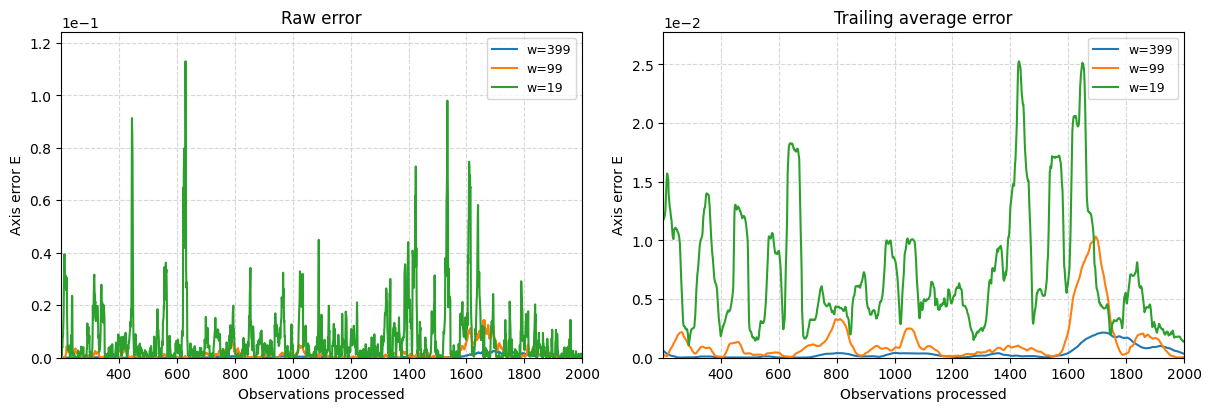

w=399 cumulative error from observation 1: 1.582685724427518
w=99 cumulative error from observation 1: 3.2757837810880117
w=19 cumulative error from observation 1: 14.616923578483242


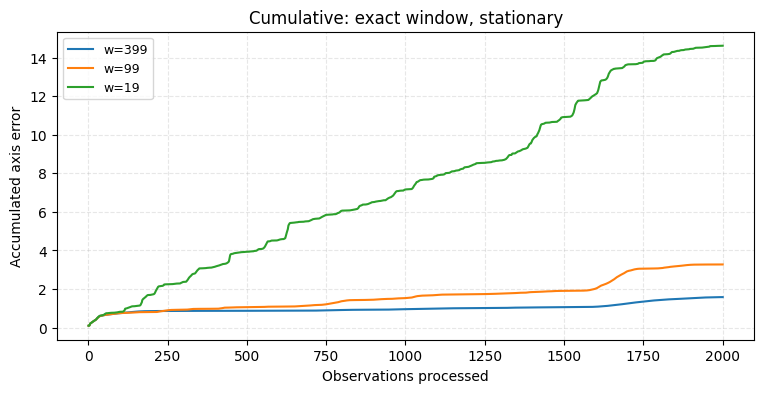

w=399 stationary angle SD (degrees): 0.7951849299130573
w=99 stationary angle SD (degrees): 1.9569447945540521
w=19 stationary angle SD (degrees): 4.78931853953564


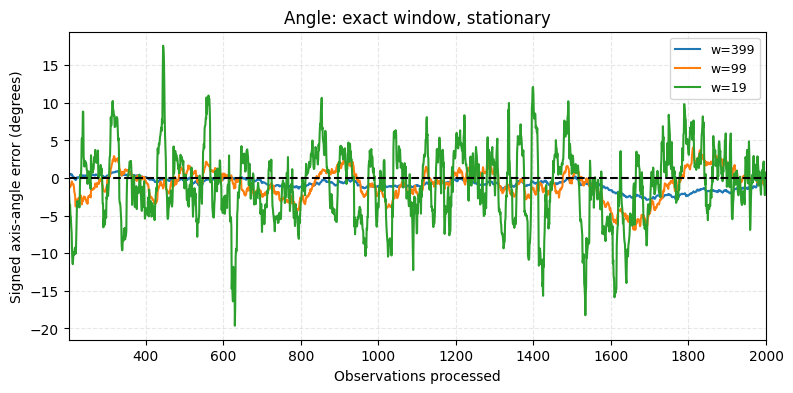

w=399 mean captured variance after warm-up (%): 90.87627115618835
w=99 mean captured variance after warm-up (%): 90.79688890262148
w=19 mean captured variance after warm-up (%): 90.32234296022449


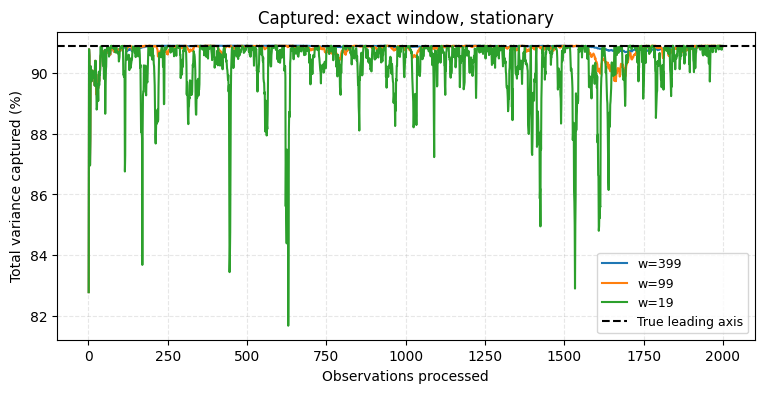

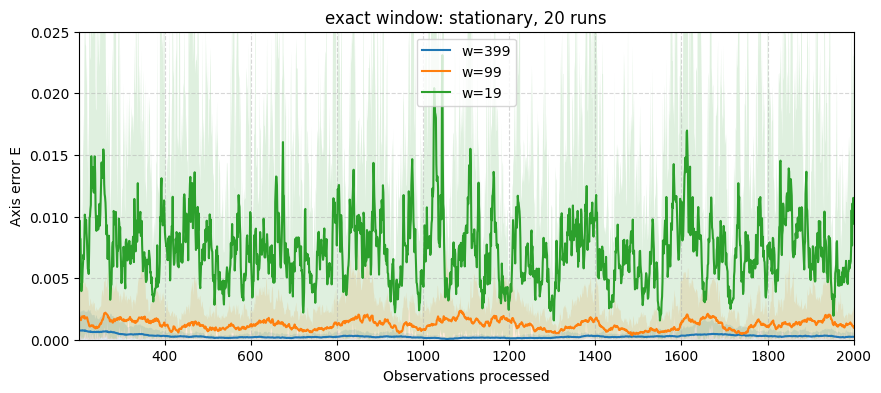

In [10]:
ut.show_plots(single['exact', 'stationary'], results['exact', 'stationary'], streams['stationary'][seed][1], 'stationary',
              settings_for['stationary'], 'exact window', window_label)

#### Repeated-run measurements

In [11]:
ut.show_repeated_measurements(results['exact', 'stationary'], 'stationary', settings_for['stationary'], window_label)

| Method | Mean E | SD of run means | Mean temporal SD |
| --- | --- | --- | --- |
| w=399 | 0.00027 | 0.00014 | 0.00033 |
| w=99 | 0.00123 | 0.00044 | 0.00167 |
| w=19 | 0.00733 | 0.00094 | 0.01159 |


### Abrupt-change data

In [12]:
single['exact', 'abrupt'] = single_run(sliding_window_cov_pca, window_sizes, streams['abrupt'][seed])

#### Single-run measurements

In [13]:
ut.show_single_run(single['exact', 'abrupt'], 'abrupt', settings_for['abrupt'], window_label)

| Method | Pre-change mean E | Post-change mean E | Final-segment mean E | Recovery delay |
| --- | --- | --- | --- | --- |
| w=399 | 0.00012 | 0.14088 | 0.00074 | 328.0 |
| w=99 | 0.00091 | 0.03642 | 0.00100 | 107.0 |
| w=19 | 0.00682 | 0.01311 | 0.00299 | 56.0 |


#### Repeat with 20 seeds

Use the shared stream stored for each seed. All sections use the same seed list. Rows in the saved array are runs, and columns are timesteps.

In [14]:
results['exact', 'abrupt'] = repeat_runs(sliding_window_cov_pca, window_sizes, streams['abrupt'], 'abrupt', settings_for['abrupt'],
                                   'Sliding-window PCA (update/downdate)', 'window_size')

Saved Sliding-window PCA (update/downdate), abrupt, alpha= to C:\Users\mesie\OneDrive\Desktop\TESI\online_pca_thesis\results\sliding_window\sliding_window_results.csv


Saved Sliding-window PCA (update/downdate), abrupt, alpha= to C:\Users\mesie\OneDrive\Desktop\TESI\online_pca_thesis\results\sliding_window\sliding_window_results.csv


Saved Sliding-window PCA (update/downdate), abrupt, alpha= to C:\Users\mesie\OneDrive\Desktop\TESI\online_pca_thesis\results\sliding_window\sliding_window_results.csv


#### Computational cost

In [15]:
ut.show_cost(results['exact', 'abrupt'], window_label)

| Method | Mean seconds | Shortest seconds | Longest seconds | SD seconds |
| --- | --- | --- | --- | --- |
| w=399 | 0.05356772000086494 | 0.049556100042536855 | 0.0546430999529548 | 0.0010419447621538393 |
| w=99 | 0.05385229499952402 | 0.04846309998538345 | 0.058072299987543374 | 0.0025798861332546404 |
| w=19 | 0.0528188849973958 | 0.04644220002228394 | 0.05514389998279512 | 0.002473142102330441 |


#### Repeated-run plot

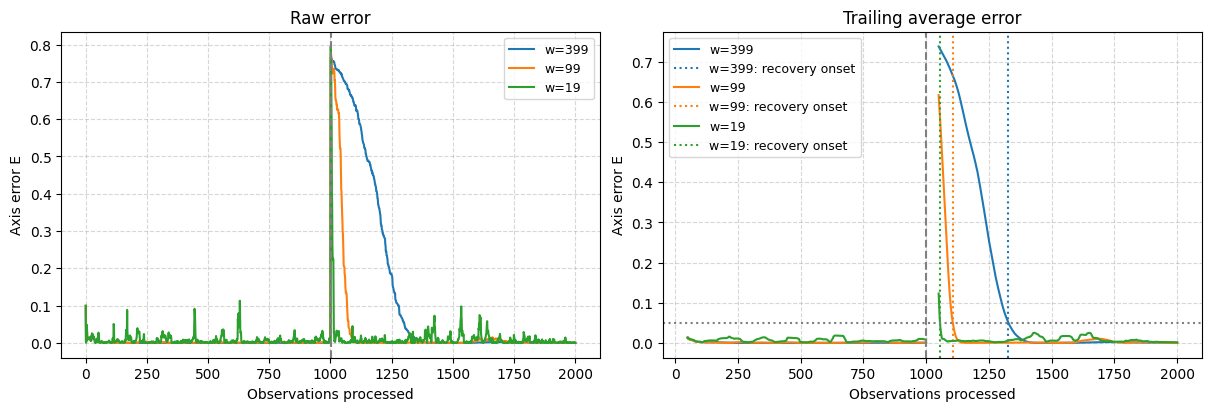

w=399 cumulative error from observation 1: 141.83454932890248
w=99 cumulative error from observation 1: 37.950920928894966
w=19 cumulative error from observation 1: 20.276561780996236


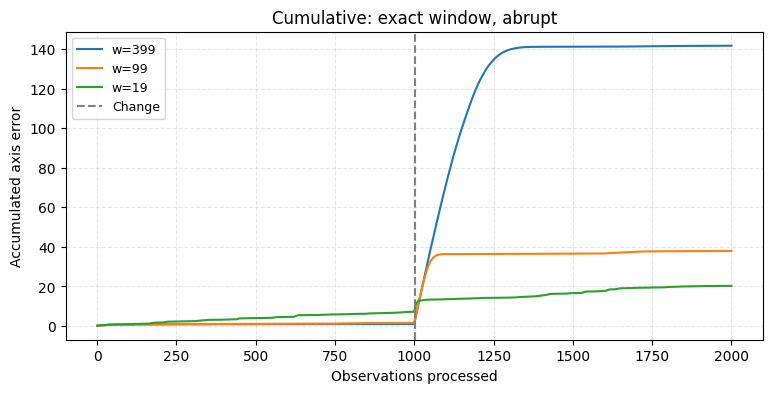

w=399 stationary angle SD (degrees): 0.5428314555674935
w=99 stationary angle SD (degrees): 1.594837486797134
w=19 stationary angle SD (degrees): 4.654328902834001


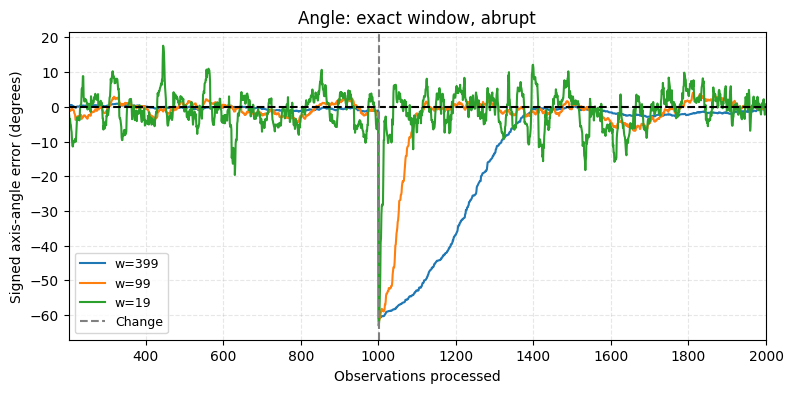

w=399 mean captured variance after warm-up (%): 84.50118644689402
w=99 mean captured variance after warm-up (%): 89.2207463049939
w=19 mean captured variance after warm-up (%): 90.06508667829209


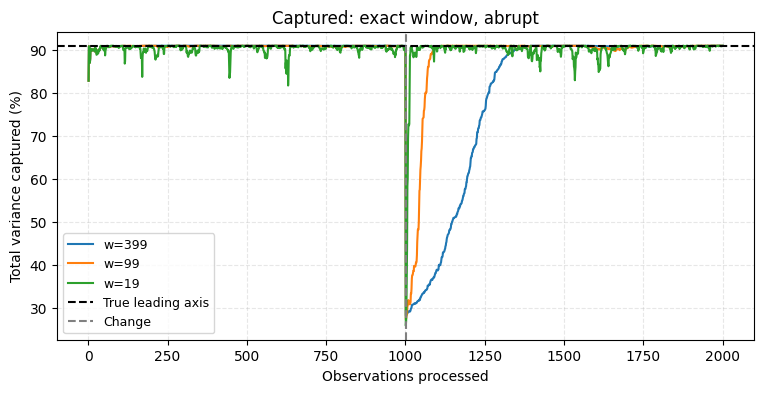

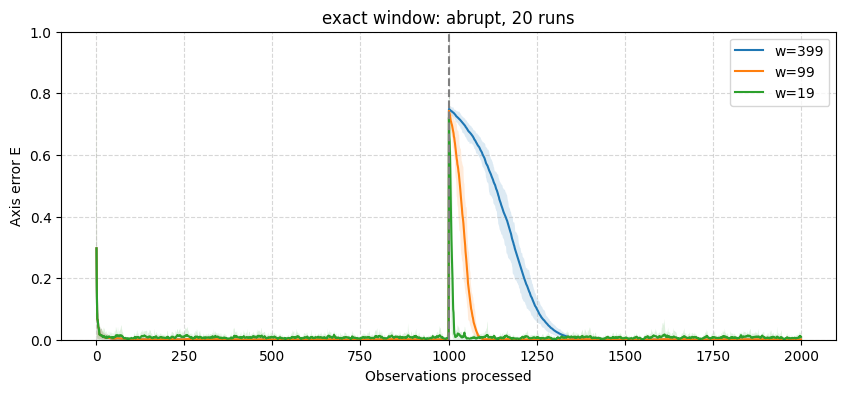

In [16]:
ut.show_plots(single['exact', 'abrupt'], results['exact', 'abrupt'], streams['abrupt'][seed][1], 'abrupt',
              settings_for['abrupt'], 'exact window', window_label)

#### Repeated-run measurements

Read the median recovery delay together with the recovered-run count: the median includes only runs that recovered.

In [17]:
ut.show_repeated_measurements(results['exact', 'abrupt'], 'abrupt', settings_for['abrupt'], window_label)

| Method | Pre-change E: mean +/- SD | Post-change E: mean +/- SD | Final E: mean +/- SD | Recovered runs | Median delay |
| --- | --- | --- | --- | --- | --- |
| w=399 | 0.00030 +/- 0.00018 | 0.12385 +/- 0.01002 | 0.00027 +/- 0.00031 | 20/20 | 304.0 |
| w=99 | 0.00125 +/- 0.00053 | 0.03163 +/- 0.00584 | 0.00136 +/- 0.00131 | 20/20 | 102.0 |
| w=19 | 0.00747 +/- 0.00146 | 0.01256 +/- 0.00269 | 0.00746 +/- 0.00301 | 20/20 | 55.0 |


### Smooth rotation data

In [18]:
single['exact', 'rotation'] = single_run(sliding_window_cov_pca, window_sizes, streams['rotation'][seed])

#### Single-run measurements

In [19]:
ut.show_single_run(single['exact', 'rotation'], 'rotation', settings_for['rotation'], window_label)

| Method | Mean error after warm-up | Temporal error SD |
| --- | --- | --- |
| w=399 | 0.04376 | 0.01091 |
| w=99 | 0.00521 | 0.00527 |
| w=19 | 0.00754 | 0.01222 |


#### Repeat with 20 seeds

In [20]:
results['exact', 'rotation'] = repeat_runs(sliding_window_cov_pca, window_sizes, streams['rotation'], 'rotation', settings_for['rotation'],
                                   'Sliding-window PCA (update/downdate)', 'window_size')

Saved Sliding-window PCA (update/downdate), rotation, alpha= to C:\Users\mesie\OneDrive\Desktop\TESI\online_pca_thesis\results\sliding_window\sliding_window_rotation_results_omega=0.001_dt=1.csv


Saved Sliding-window PCA (update/downdate), rotation, alpha= to C:\Users\mesie\OneDrive\Desktop\TESI\online_pca_thesis\results\sliding_window\sliding_window_rotation_results_omega=0.001_dt=1.csv


Saved Sliding-window PCA (update/downdate), rotation, alpha= to C:\Users\mesie\OneDrive\Desktop\TESI\online_pca_thesis\results\sliding_window\sliding_window_rotation_results_omega=0.001_dt=1.csv


#### Computational cost

In [21]:
ut.show_cost(results['exact', 'rotation'], window_label)

| Method | Mean seconds | Shortest seconds | Longest seconds | SD seconds |
| --- | --- | --- | --- | --- |
| w=399 | 0.05159290000447072 | 0.04600410000421107 | 0.06153260002611205 | 0.0036062401953091527 |
| w=99 | 0.053873740005656146 | 0.047260899969842285 | 0.06493230001069605 | 0.004130593283618854 |
| w=19 | 0.05774637500871904 | 0.055310600029770285 | 0.06506290001561865 | 0.002302307278515248 |


#### Repeated-run plot

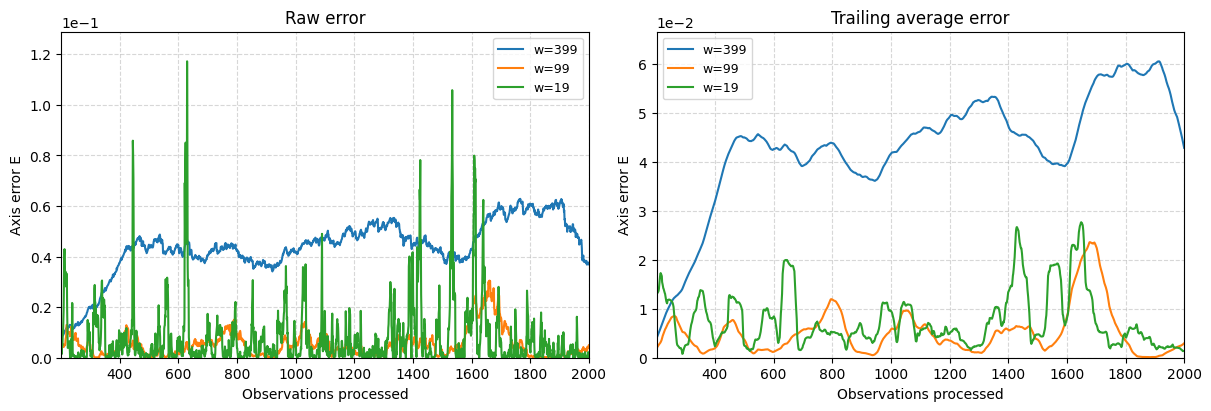

w=399 cumulative error from observation 1: 79.55295909403598
w=99 cumulative error from observation 1: 10.06014665925345
w=19 cumulative error from observation 1: 15.297160707626015


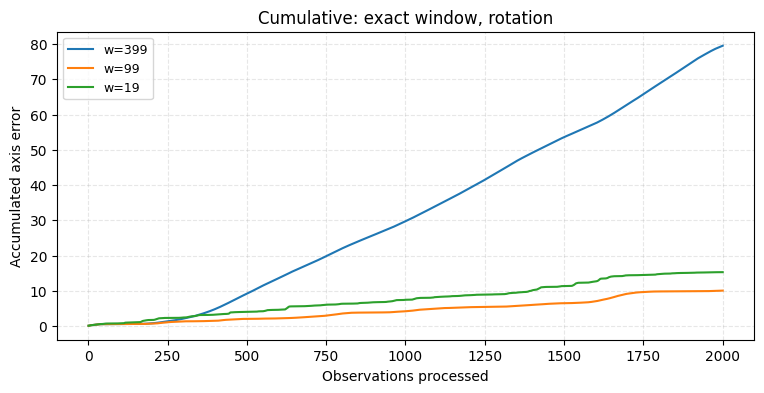

w=399 tracking angle-error SD (degrees): 1.7330033285936006
w=99 tracking angle-error SD (degrees): 1.9964817624482658
w=19 tracking angle-error SD (degrees): 4.793350840620599


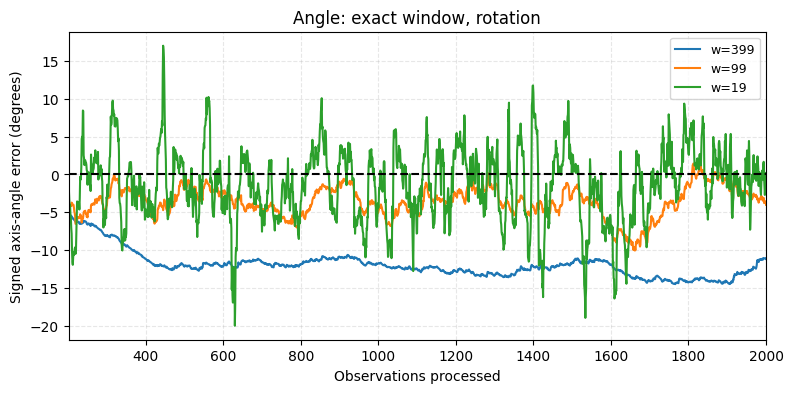

w=399 mean captured variance after warm-up (%): 87.32844964501442
w=99 mean captured variance after warm-up (%): 90.48287659548478
w=19 mean captured variance after warm-up (%): 90.2921876236711


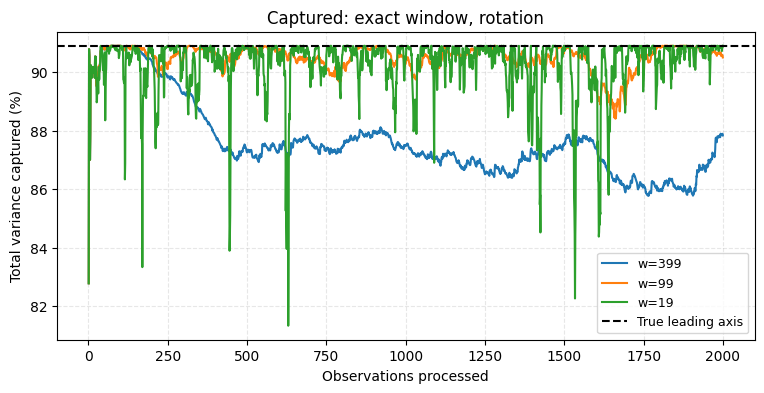

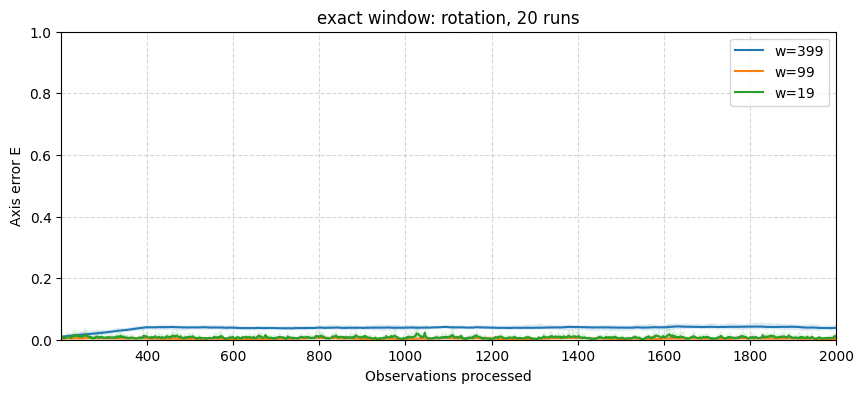

In [22]:
ut.show_plots(single['exact', 'rotation'], results['exact', 'rotation'], streams['rotation'][seed][1], 'rotation',
              settings_for['rotation'], 'exact window', window_label)

#### Repeated-run measurements

In [23]:
ut.show_repeated_measurements(results['exact', 'rotation'], 'rotation', settings_for['rotation'], window_label)

| Method | Mean E | SD of run means | Mean temporal SD |
| --- | --- | --- | --- |
| w=399 | 0.03811 | 0.00271 | 0.00843 |
| w=99 | 0.00381 | 0.00103 | 0.00393 |
| w=19 | 0.00744 | 0.00102 | 0.01174 |


### Random drift data

In [24]:
single['exact', 'drift'] = single_run(sliding_window_cov_pca, window_sizes, streams['drift'][seed])

#### Single-run measurements

In [25]:
ut.show_single_run(single['exact', 'drift'], 'drift', settings_for['drift'], window_label)

| Method | Mean error after warm-up | Temporal error SD |
| --- | --- | --- |
| w=399 | 0.01931 | 0.02297 |
| w=99 | 0.00613 | 0.00939 |
| w=19 | 0.00890 | 0.01384 |


#### Repeat with 20 seeds

In [26]:
results['exact', 'drift'] = repeat_runs(sliding_window_cov_pca, window_sizes, streams['drift'], 'drift', settings_for['drift'],
                                   'Sliding-window PCA (update/downdate)', 'window_size')

Saved Sliding-window PCA (update/downdate), drift, alpha= to C:\Users\mesie\OneDrive\Desktop\TESI\online_pca_thesis\results\sliding_window\sliding_window_drift_results_Q=0.0001_dt=1.csv


Saved Sliding-window PCA (update/downdate), drift, alpha= to C:\Users\mesie\OneDrive\Desktop\TESI\online_pca_thesis\results\sliding_window\sliding_window_drift_results_Q=0.0001_dt=1.csv


Saved Sliding-window PCA (update/downdate), drift, alpha= to C:\Users\mesie\OneDrive\Desktop\TESI\online_pca_thesis\results\sliding_window\sliding_window_drift_results_Q=0.0001_dt=1.csv


#### Computational cost

In [27]:
ut.show_cost(results['exact', 'drift'], window_label)

| Method | Mean seconds | Shortest seconds | Longest seconds | SD seconds |
| --- | --- | --- | --- | --- |
| w=399 | 0.05475011500529945 | 0.04931839997880161 | 0.05961649998789653 | 0.0025323011029596016 |
| w=99 | 0.0560846349952044 | 0.05297169997356832 | 0.060796700010541826 | 0.0020811064370914573 |
| w=19 | 0.05306420999986585 | 0.04721669998252764 | 0.0590183999738656 | 0.003244120176635713 |


#### Repeated-run plot

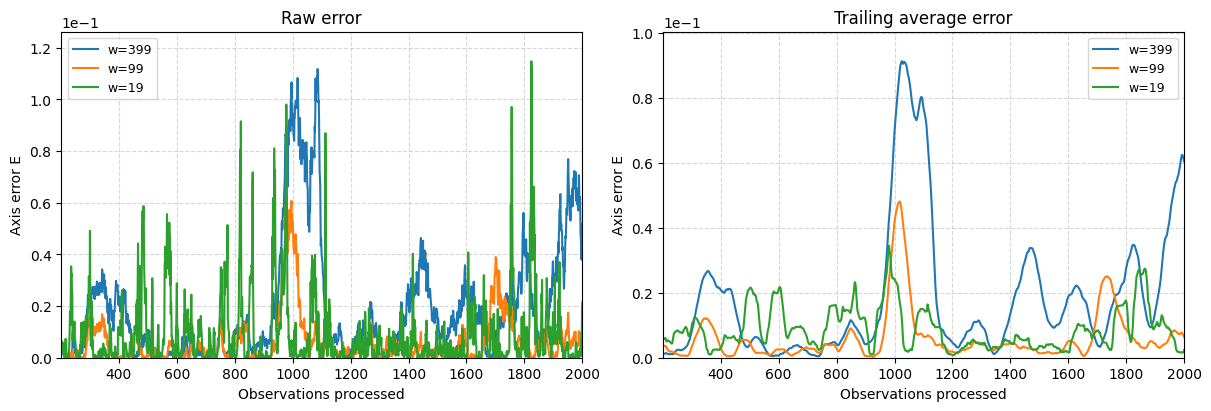

w=399 cumulative error from observation 1: 36.39282888765707
w=99 cumulative error from observation 1: 12.82784410477403
w=19 cumulative error from observation 1: 18.647452774312843


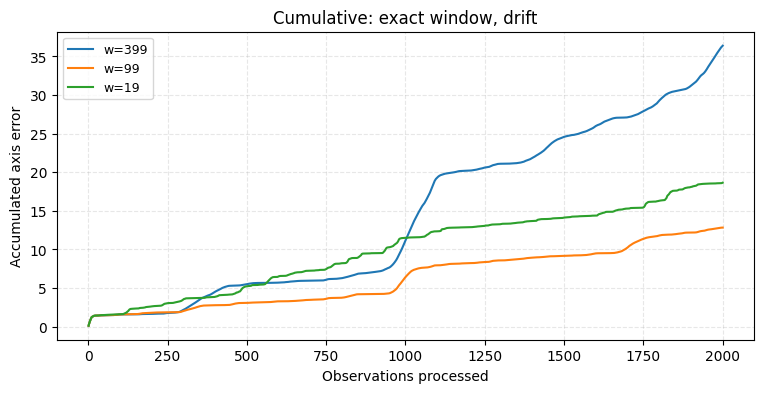

w=399 tracking angle-error SD (degrees): 7.0132222983354815
w=99 tracking angle-error SD (degrees): 4.181562902567312
w=19 tracking angle-error SD (degrees): 5.338135166562444


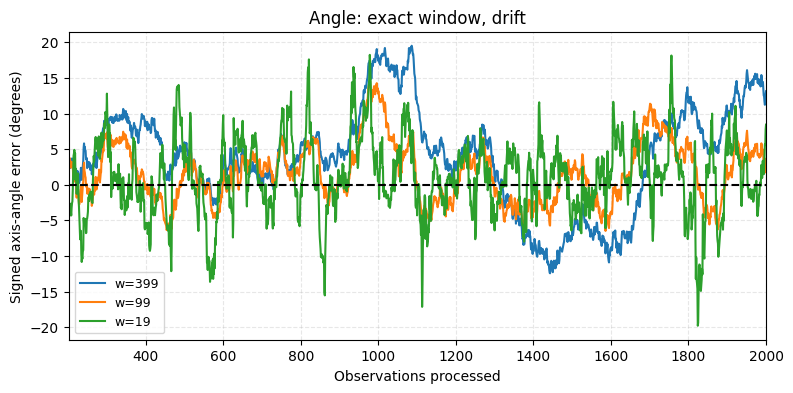

w=399 mean captured variance after warm-up (%): 89.32953483185695
w=99 mean captured variance after warm-up (%): 90.40767703444622
w=19 mean captured variance after warm-up (%): 90.18055601960161


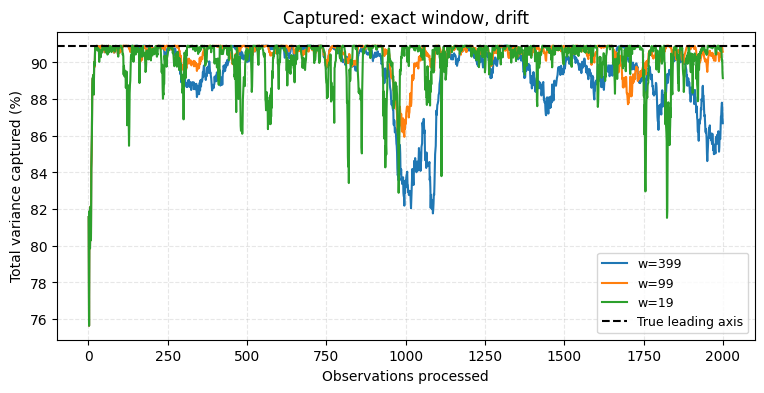

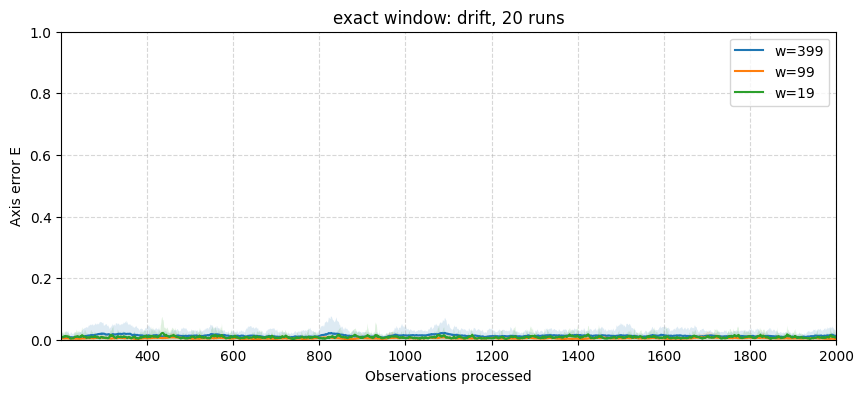

In [28]:
ut.show_plots(single['exact', 'drift'], results['exact', 'drift'], streams['drift'][seed][1], 'drift',
              settings_for['drift'], 'exact window', window_label)

#### Repeated-run measurements

In [29]:
ut.show_repeated_measurements(results['exact', 'drift'], 'drift', settings_for['drift'], window_label)

| Method | Mean E | SD of run means | Mean temporal SD |
| --- | --- | --- | --- |
| w=399 | 0.01273 | 0.00417 | 0.01586 |
| w=99 | 0.00469 | 0.00083 | 0.00608 |
| w=19 | 0.00823 | 0.00111 | 0.01267 |


## 2. Sliding-window PCA (rank-1 SVD update/downdate)

### Theory: SVD update/downdate and truncation

The idea of this method is to keep a compressed version of the window and to change it one observation at a time, instead of storing the full window matrix $S=\sum x_kx_k^\top$ (sum over the last $w$ observations).

**1. The compressed window.** We keep only the main directions of $S$:

$$S\approx U\,\mathrm{diag}(s^2)\,U^\top ,$$

where the columns of $U$ are the $r$ retained directions (here $r=1$, the principal axis) and $s^2$ is the variance along each of them.

**2. Splitting a new observation.** A new observation $x$ is split into the part along the directions we already have, $UU^\top x$, and the part they do not explain:

$$\rho=x-UU^\top x,\qquad \hat\rho=\rho/\lVert\rho\rVert .$$

**3. The small problem.** Adding or removing $x$ can be written using only the old directions and the new direction $\hat\rho$:

$$S\pm xx^\top=[U\ \hat\rho]\left(\begin{bmatrix}\mathrm{diag}(s^2)&0\\0&0\end{bmatrix}\pm zz^\top\right)[U\ \hat\rho]^\top,\qquad z=\begin{bmatrix}U^\top x\\ \lVert\rho\rVert\end{bmatrix}.$$

Here $z$ is the observation written in this small basis (its coordinates along $U$ and the size of the leftover part). So instead of working with the full matrix, we only need the eigenvectors of the small matrix in the middle, which is $(r+1)\times(r+1)$ ($2\times2$ in our case). They give the new directions. This small problem, a diagonal matrix plus a rank-one term, is the symmetric rank-one modification of Bunch, Nielsen and Sorensen (1978); the construction in the basis $[U,\hat\rho]$ follows Brand (2006). Here it is solved with a standard symmetric eigensolver. (`svd_rank_one_modify`, `sliding_window_svd_pca`)

**4. Update and downdate.** The sign is the only difference:
- $+$ (**update**): the newest observation $x_n$ enters the window;
- $-$ (**downdate**): the oldest one, $x_{n-w}$, leaves.

At each step we do both, so the window always contains $w$ observations.

**5. Truncation.** The small problem gives $r+1$ directions, and we keep only the $r$ strongest.
- With $r=2$ in 2D nothing is thrown away, and the result is exactly the window covariance. We use this only as a check (Section 4).
- With $r=1$, used here, the perpendicular part is thrown away after each step. The update then works like the rank-1 SVD forgetting PCA of `01_baselines`. The downdate, however, is not exact: when an old observation leaves, it is removed using the current direction, not the one it entered with, and the part that was thrown away when it entered is not there anymore. In a window nothing fades away, so these small errors stay. Section 5 studies their effect.


### Stationary data

In [30]:
single['svd', 'stationary'] = single_run(sliding_window_svd_pca, window_sizes, streams['stationary'][seed])

#### Single-run measurements

In [31]:
ut.show_single_run(single['svd', 'stationary'], 'stationary', settings_for['stationary'], window_label)

| Method | Mean error after warm-up | Temporal error SD |
| --- | --- | --- |
| w=399 | 0.00026 | 0.00038 |
| w=99 | 0.00097 | 0.00145 |
| w=19 | 0.00600 | 0.00983 |


#### Repeat with 20 seeds

In [32]:
results['svd', 'stationary'] = repeat_runs(sliding_window_svd_pca, window_sizes, streams['stationary'], 'stationary', settings_for['stationary'],
                                   'Sliding-window PCA (rank-1 SVD)', 'window_size')

Saved Sliding-window PCA (rank-1 SVD), stationary, alpha= to C:\Users\mesie\OneDrive\Desktop\TESI\online_pca_thesis\results\sliding_window\sliding_window_results.csv


Saved Sliding-window PCA (rank-1 SVD), stationary, alpha= to C:\Users\mesie\OneDrive\Desktop\TESI\online_pca_thesis\results\sliding_window\sliding_window_results.csv


Saved Sliding-window PCA (rank-1 SVD), stationary, alpha= to C:\Users\mesie\OneDrive\Desktop\TESI\online_pca_thesis\results\sliding_window\sliding_window_results.csv


#### Computational cost

In [33]:
ut.show_cost(results['svd', 'stationary'], window_label)

| Method | Mean seconds | Shortest seconds | Longest seconds | SD seconds |
| --- | --- | --- | --- | --- |
| w=399 | 0.07775113499956206 | 0.06748540000990033 | 0.08248670003376901 | 0.00511886594124839 |
| w=99 | 0.08968381500744727 | 0.0767731000087224 | 0.11573799996403977 | 0.009672603403698575 |
| w=19 | 0.08429937999753748 | 0.07608159998198971 | 0.09200800000689924 | 0.005474364533713699 |


#### Repeated-run plot

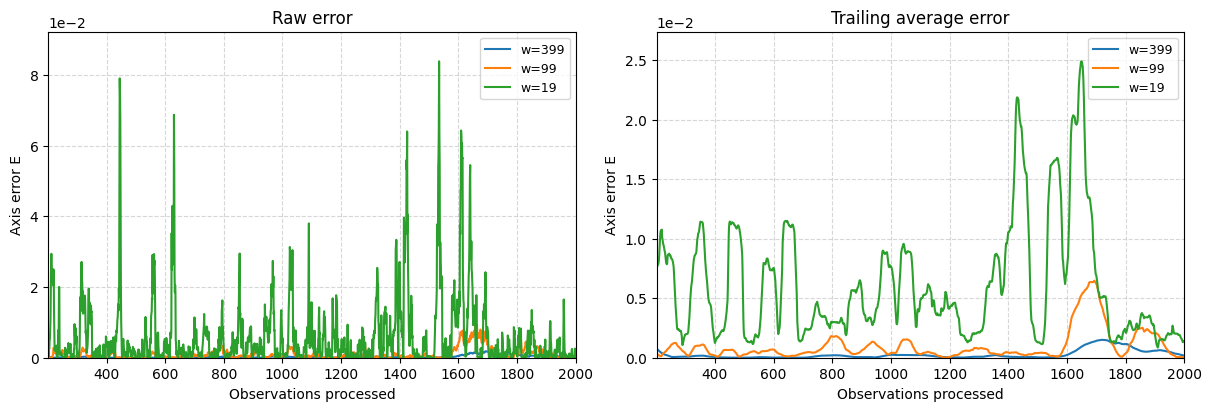

w=399 cumulative error from observation 1: 1.3655809492663127
w=99 cumulative error from observation 1: 2.5931851043454186
w=19 cumulative error from observation 1: 12.156989265147473


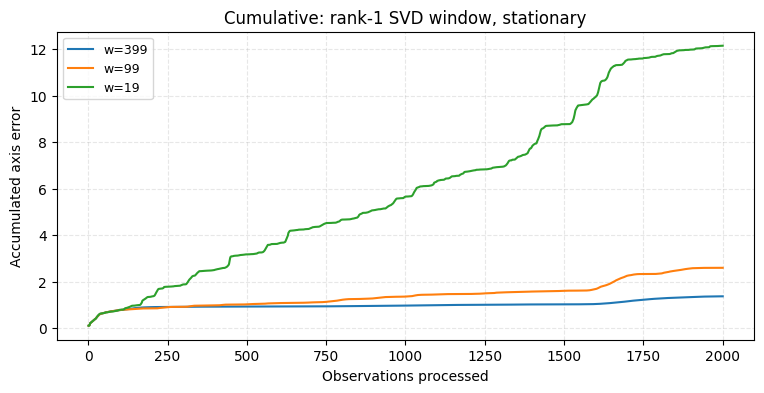

w=399 stationary angle SD (degrees): 0.72369748417654
w=99 stationary angle SD (degrees): 1.7677678754118644
w=19 stationary angle SD (degrees): 4.241472663333467


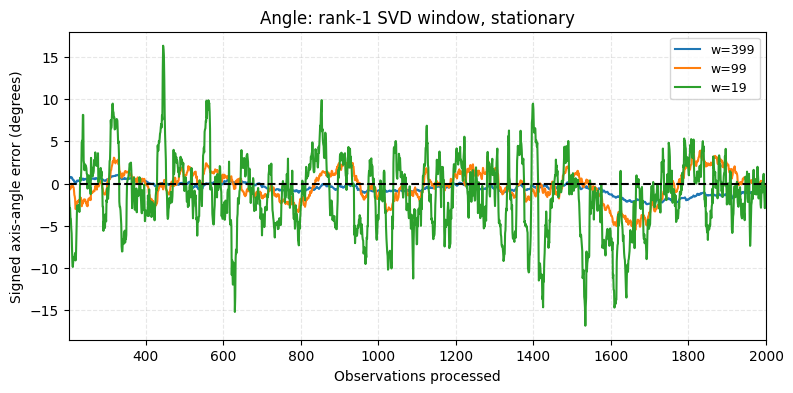

w=399 mean captured variance after warm-up (%): 90.88799507647747
w=99 mean captured variance after warm-up (%): 90.8296810556044
w=19 mean captured variance after warm-up (%): 90.41818664327121


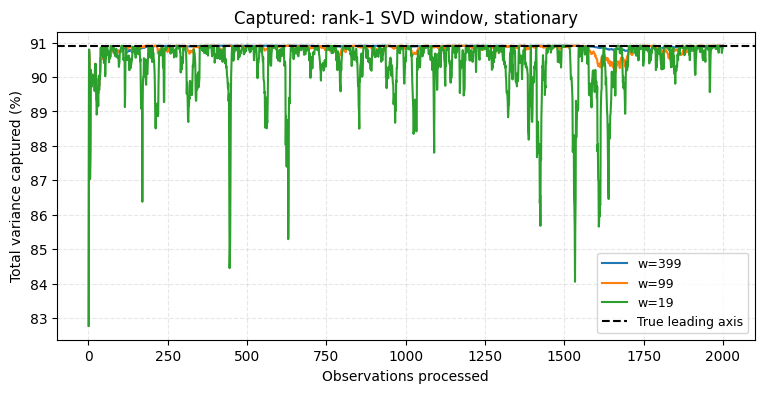

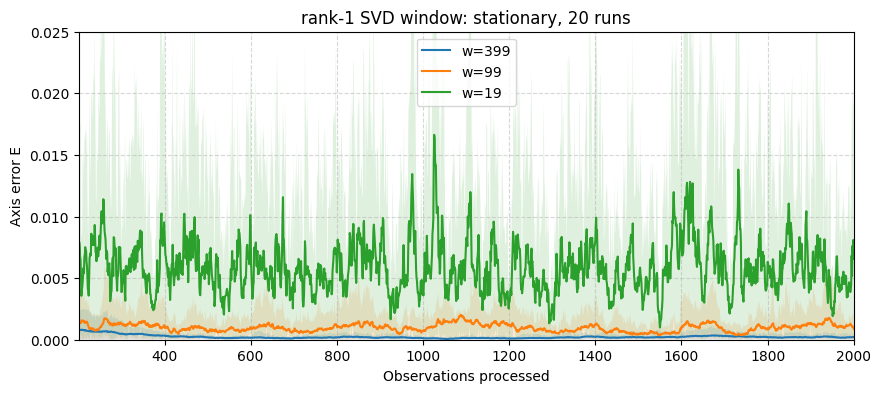

In [34]:
ut.show_plots(single['svd', 'stationary'], results['svd', 'stationary'], streams['stationary'][seed][1], 'stationary',
              settings_for['stationary'], 'rank-1 SVD window', window_label)

#### Repeated-run measurements

In [35]:
ut.show_repeated_measurements(results['svd', 'stationary'], 'stationary', settings_for['stationary'], window_label)

| Method | Mean E | SD of run means | Mean temporal SD |
| --- | --- | --- | --- |
| w=399 | 0.00023 | 0.00013 | 0.00029 |
| w=99 | 0.00099 | 0.00035 | 0.00135 |
| w=19 | 0.00589 | 0.00076 | 0.00874 |


### Abrupt-change data

In [36]:
single['svd', 'abrupt'] = single_run(sliding_window_svd_pca, window_sizes, streams['abrupt'][seed])

#### Single-run measurements

In [37]:
ut.show_single_run(single['svd', 'abrupt'], 'abrupt', settings_for['abrupt'], window_label)

| Method | Pre-change mean E | Post-change mean E | Final-segment mean E | Recovery delay |
| --- | --- | --- | --- | --- |
| w=399 | 0.00008 | 0.21592 | 0.06199 | nan |
| w=99 | 0.00064 | 0.09749 | 0.04418 | 145.0 |
| w=19 | 0.00537 | 0.05875 | 0.01361 | 369.0 |


#### Repeat with 20 seeds

In [38]:
results['svd', 'abrupt'] = repeat_runs(sliding_window_svd_pca, window_sizes, streams['abrupt'], 'abrupt', settings_for['abrupt'],
                                   'Sliding-window PCA (rank-1 SVD)', 'window_size')

Saved Sliding-window PCA (rank-1 SVD), abrupt, alpha= to C:\Users\mesie\OneDrive\Desktop\TESI\online_pca_thesis\results\sliding_window\sliding_window_results.csv


Saved Sliding-window PCA (rank-1 SVD), abrupt, alpha= to C:\Users\mesie\OneDrive\Desktop\TESI\online_pca_thesis\results\sliding_window\sliding_window_results.csv


Saved Sliding-window PCA (rank-1 SVD), abrupt, alpha= to C:\Users\mesie\OneDrive\Desktop\TESI\online_pca_thesis\results\sliding_window\sliding_window_results.csv


#### Computational cost

In [39]:
ut.show_cost(results['svd', 'abrupt'], window_label)

| Method | Mean seconds | Shortest seconds | Longest seconds | SD seconds |
| --- | --- | --- | --- | --- |
| w=399 | 0.0873638650024077 | 0.08039810002082959 | 0.10936679999576882 | 0.007217728252409517 |
| w=99 | 0.08573889000108466 | 0.07375550002325326 | 0.1134885000064969 | 0.009019169234295523 |
| w=19 | 0.09065435499942395 | 0.07810719998087734 | 0.0974358000094071 | 0.005442640655302219 |


#### Repeated-run plot

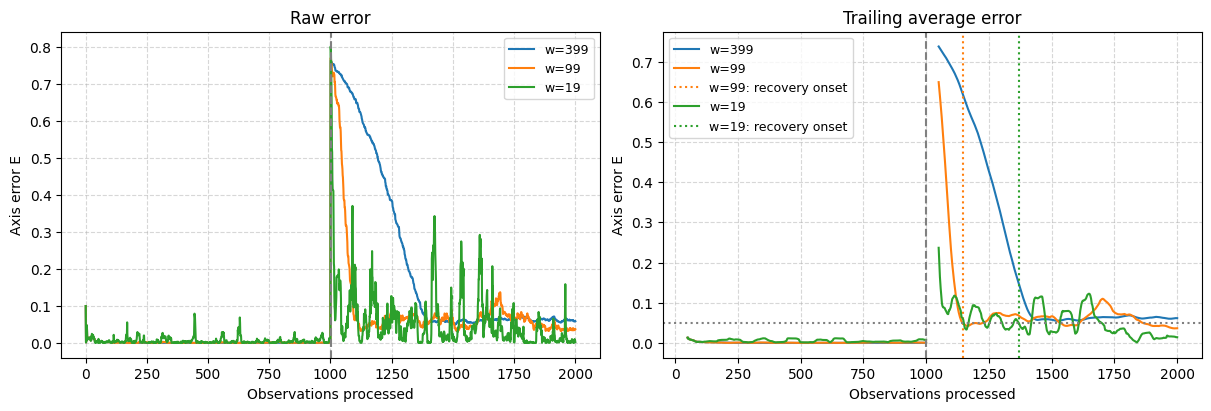

w=399 cumulative error from observation 1: 216.88177292255017
w=99 cumulative error from observation 1: 98.8451309843991
w=19 cumulative error from observation 1: 64.41067754676774


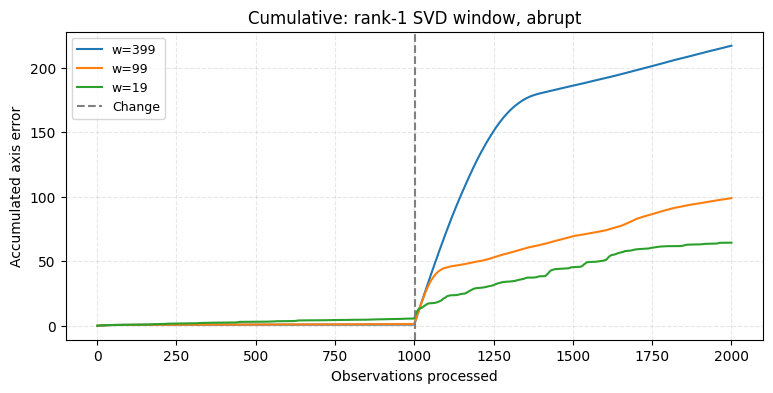

w=399 stationary angle SD (degrees): 0.5055601070347564
w=99 stationary angle SD (degrees): 1.4395512668737938
w=19 stationary angle SD (degrees): 4.16877694253152


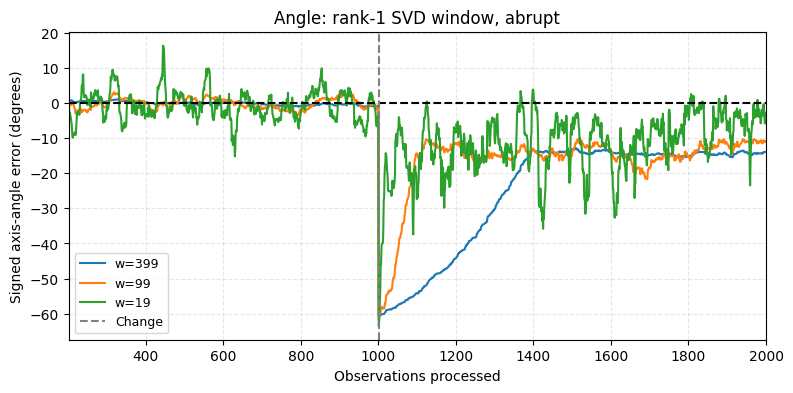

w=399 mean captured variance after warm-up (%): 81.09180453223728
w=99 mean captured variance after warm-up (%): 86.45459260651106
w=19 mean captured variance after warm-up (%): 88.04301899410666


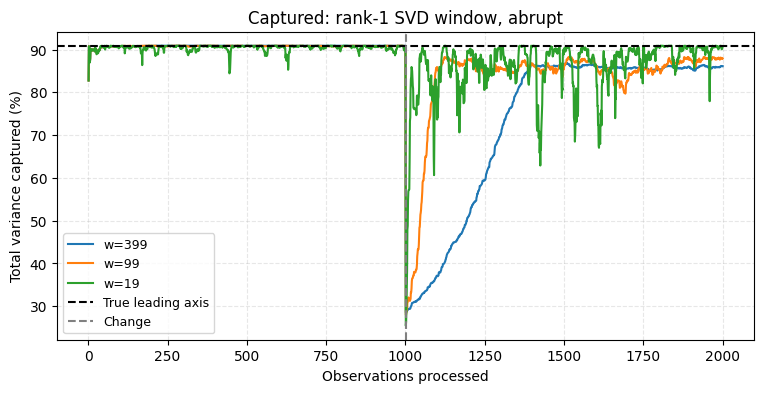

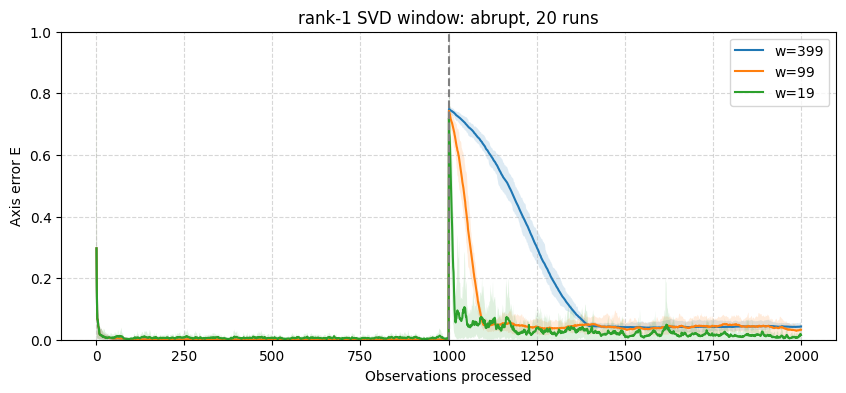

In [40]:
ut.show_plots(single['svd', 'abrupt'], results['svd', 'abrupt'], streams['abrupt'][seed][1], 'abrupt',
              settings_for['abrupt'], 'rank-1 SVD window', window_label)

#### Repeated-run measurements

In [41]:
ut.show_repeated_measurements(results['svd', 'abrupt'], 'abrupt', settings_for['abrupt'], window_label)

| Method | Pre-change E: mean +/- SD | Post-change E: mean +/- SD | Final E: mean +/- SD | Recovered runs | Median delay |
| --- | --- | --- | --- | --- | --- |
| w=399 | 0.00027 +/- 0.00021 | 0.18879 +/- 0.01175 | 0.04291 +/- 0.00964 | 19/20 | 419.0 |
| w=99 | 0.00099 +/- 0.00043 | 0.07810 +/- 0.01120 | 0.04060 +/- 0.01461 | 20/20 | 176.0 |
| w=19 | 0.00587 +/- 0.00108 | 0.03259 +/- 0.01080 | 0.01188 +/- 0.00685 | 20/20 | 124.0 |


### Smooth rotation data

In [42]:
single['svd', 'rotation'] = single_run(sliding_window_svd_pca, window_sizes, streams['rotation'][seed])

#### Single-run measurements

In [43]:
ut.show_single_run(single['svd', 'rotation'], 'rotation', settings_for['rotation'], window_label)

| Method | Mean error after warm-up | Temporal error SD |
| --- | --- | --- |
| w=399 | 0.07344 | 0.02663 |
| w=99 | 0.01634 | 0.01115 |
| w=19 | 0.01518 | 0.02253 |


#### Repeat with 20 seeds

In [44]:
results['svd', 'rotation'] = repeat_runs(sliding_window_svd_pca, window_sizes, streams['rotation'], 'rotation', settings_for['rotation'],
                                   'Sliding-window PCA (rank-1 SVD)', 'window_size')

Saved Sliding-window PCA (rank-1 SVD), rotation, alpha= to C:\Users\mesie\OneDrive\Desktop\TESI\online_pca_thesis\results\sliding_window\sliding_window_rotation_results_omega=0.001_dt=1.csv


Saved Sliding-window PCA (rank-1 SVD), rotation, alpha= to C:\Users\mesie\OneDrive\Desktop\TESI\online_pca_thesis\results\sliding_window\sliding_window_rotation_results_omega=0.001_dt=1.csv


Saved Sliding-window PCA (rank-1 SVD), rotation, alpha= to C:\Users\mesie\OneDrive\Desktop\TESI\online_pca_thesis\results\sliding_window\sliding_window_rotation_results_omega=0.001_dt=1.csv


#### Computational cost

In [45]:
ut.show_cost(results['svd', 'rotation'], window_label)

| Method | Mean seconds | Shortest seconds | Longest seconds | SD seconds |
| --- | --- | --- | --- | --- |
| w=399 | 0.07989692500559613 | 0.06955119996564463 | 0.08356410003034398 | 0.004141079623955695 |
| w=99 | 0.08871585500310175 | 0.08084599999710917 | 0.09642359998542815 | 0.0040099040613151265 |
| w=19 | 0.09025530500221066 | 0.07791009999345988 | 0.12087790004443377 | 0.009969737850674301 |


#### Repeated-run plot

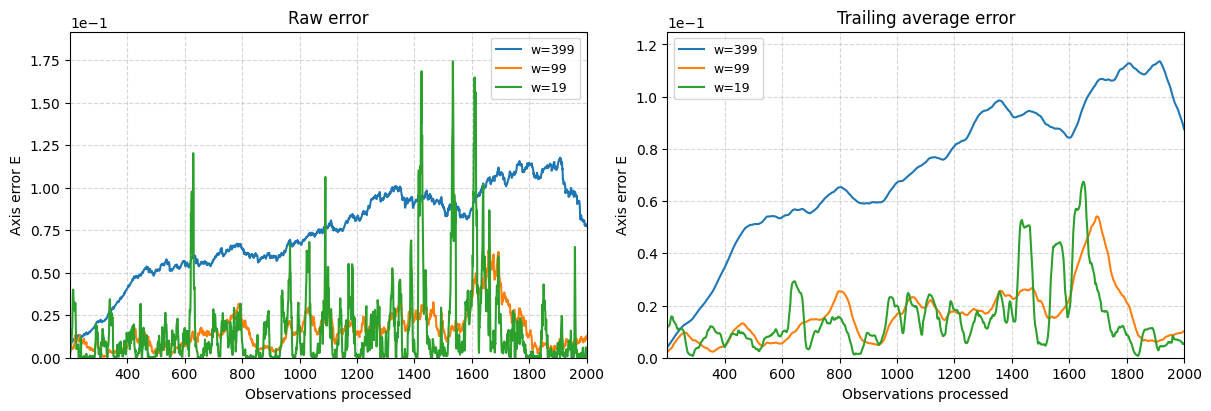

w=399 cumulative error from observation 1: 132.97742927777972
w=99 cumulative error from observation 1: 30.117972626982418
w=19 cumulative error from observation 1: 28.80207041600885


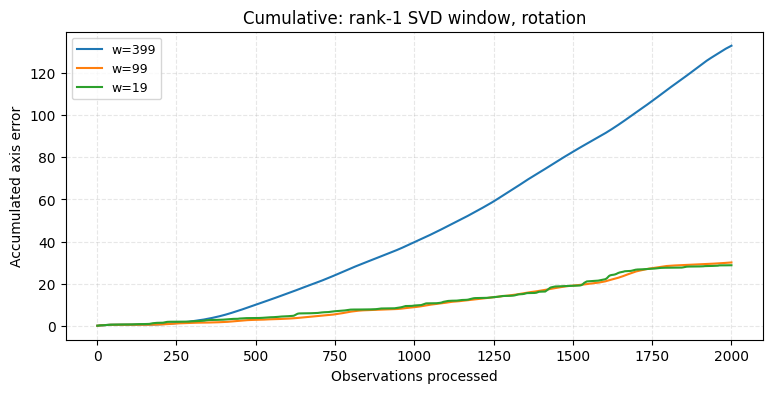

w=399 tracking angle-error SD (degrees): 3.2939951293808982
w=99 tracking angle-error SD (degrees): 2.411321509119889
w=19 tracking angle-error SD (degrees): 5.035692088912035


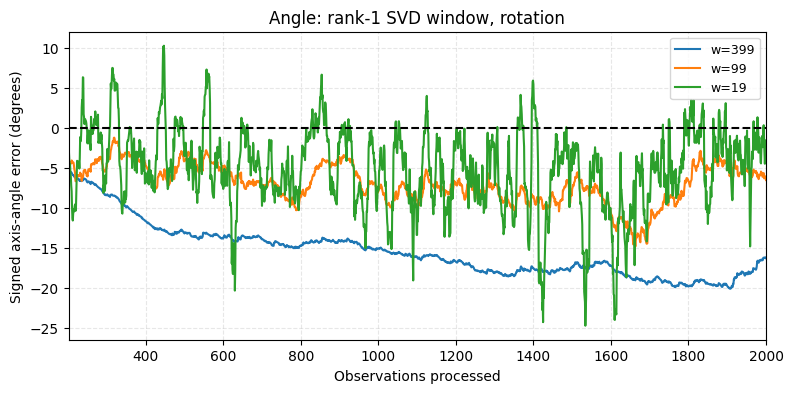

w=399 mean captured variance after warm-up (%): 84.9007224472923
w=99 mean captured variance after warm-up (%): 89.57223566912646
w=19 mean captured variance after warm-up (%): 89.6668098871796


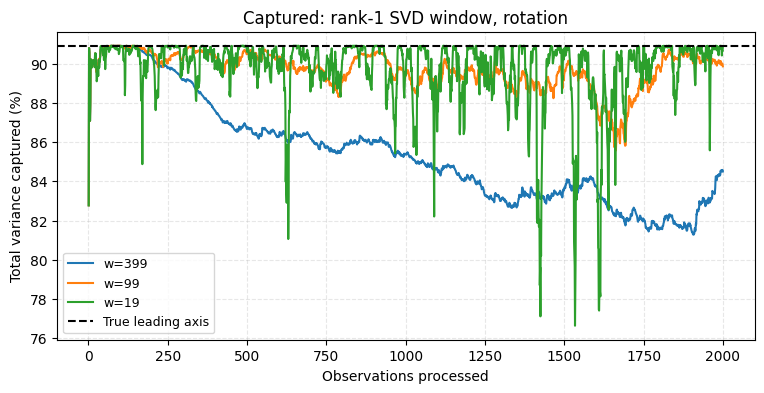

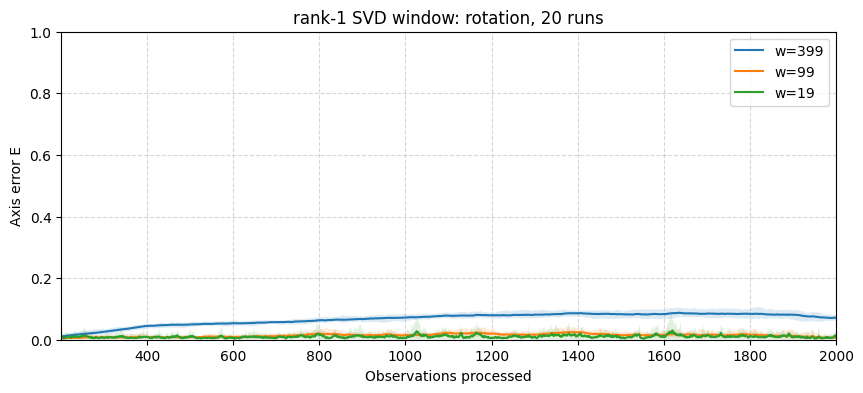

In [46]:
ut.show_plots(single['svd', 'rotation'], results['svd', 'rotation'], streams['rotation'][seed][1], 'rotation',
              settings_for['rotation'], 'rank-1 SVD window', window_label)

#### Repeated-run measurements

In [47]:
ut.show_repeated_measurements(results['svd', 'rotation'], 'rotation', settings_for['rotation'], window_label)

| Method | Mean E | SD of run means | Mean temporal SD |
| --- | --- | --- | --- |
| w=399 | 0.06740 | 0.00414 | 0.02056 |
| w=99 | 0.01427 | 0.00250 | 0.00954 |
| w=19 | 0.01000 | 0.00207 | 0.01516 |


### Random drift data

In [48]:
single['svd', 'drift'] = single_run(sliding_window_svd_pca, window_sizes, streams['drift'][seed])

#### Single-run measurements

In [49]:
ut.show_single_run(single['svd', 'drift'], 'drift', settings_for['drift'], window_label)

| Method | Mean error after warm-up | Temporal error SD |
| --- | --- | --- |
| w=399 | 0.02248 | 0.02781 |
| w=99 | 0.00842 | 0.01258 |
| w=19 | 0.00942 | 0.01405 |


#### Repeat with 20 seeds

In [50]:
results['svd', 'drift'] = repeat_runs(sliding_window_svd_pca, window_sizes, streams['drift'], 'drift', settings_for['drift'],
                                   'Sliding-window PCA (rank-1 SVD)', 'window_size')

Saved Sliding-window PCA (rank-1 SVD), drift, alpha= to C:\Users\mesie\OneDrive\Desktop\TESI\online_pca_thesis\results\sliding_window\sliding_window_drift_results_Q=0.0001_dt=1.csv


Saved Sliding-window PCA (rank-1 SVD), drift, alpha= to C:\Users\mesie\OneDrive\Desktop\TESI\online_pca_thesis\results\sliding_window\sliding_window_drift_results_Q=0.0001_dt=1.csv


Saved Sliding-window PCA (rank-1 SVD), drift, alpha= to C:\Users\mesie\OneDrive\Desktop\TESI\online_pca_thesis\results\sliding_window\sliding_window_drift_results_Q=0.0001_dt=1.csv


#### Computational cost

In [51]:
ut.show_cost(results['svd', 'drift'], window_label)

| Method | Mean seconds | Shortest seconds | Longest seconds | SD seconds |
| --- | --- | --- | --- | --- |
| w=399 | 0.07611096501350403 | 0.0682657000143081 | 0.08048569998936728 | 0.0044598878018135635 |
| w=99 | 0.08099482500110752 | 0.07486540003446862 | 0.08694549999199808 | 0.004685127582686102 |
| w=19 | 0.0800048750010319 | 0.075761100044474 | 0.08942939998814836 | 0.00397636909278565 |


#### Repeated-run plot

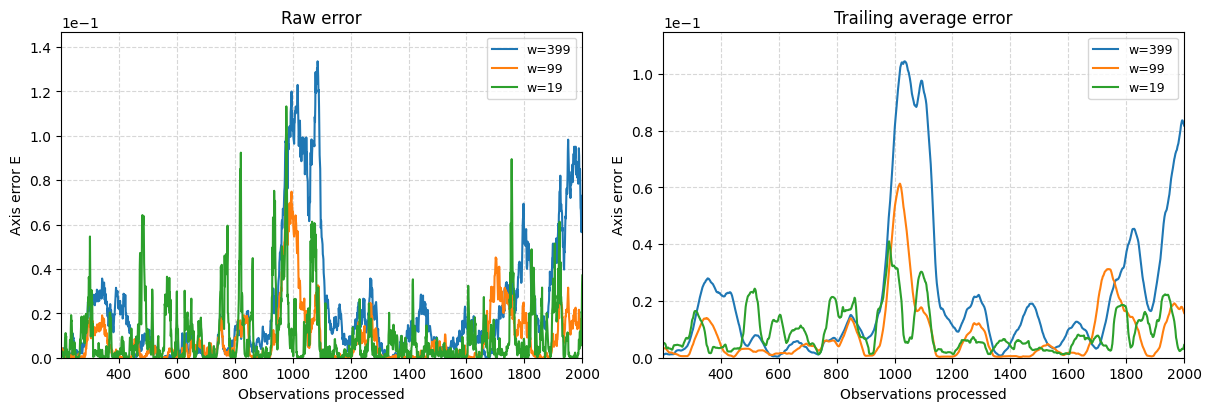

w=399 cumulative error from observation 1: 42.1837429267839
w=99 cumulative error from observation 1: 17.003926276407245
w=19 cumulative error from observation 1: 19.624838944570566


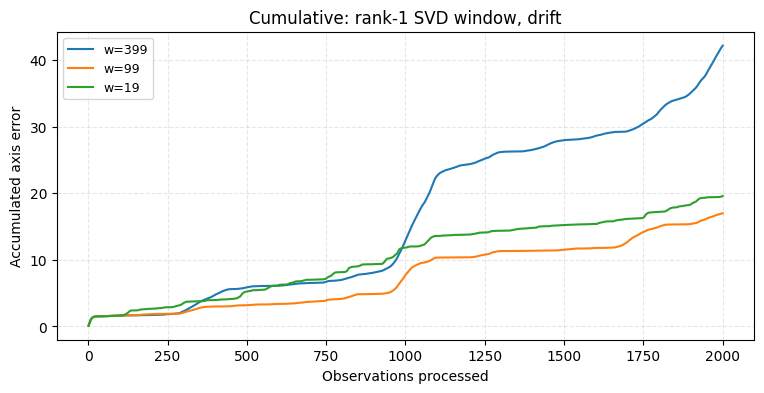

w=399 tracking angle-error SD (degrees): 6.807711121126148
w=99 tracking angle-error SD (degrees): 4.034067029205683
w=19 tracking angle-error SD (degrees): 4.924484518016787


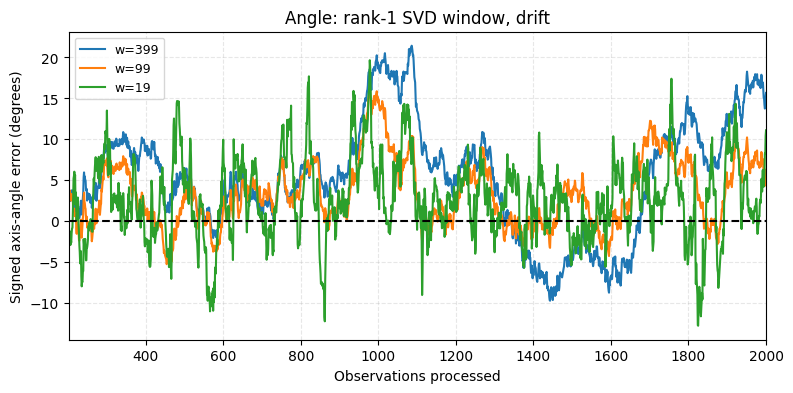

w=399 mean captured variance after warm-up (%): 89.06999262204674
w=99 mean captured variance after warm-up (%): 90.22029871246167
w=19 mean captured variance after warm-up (%): 90.13850302822364


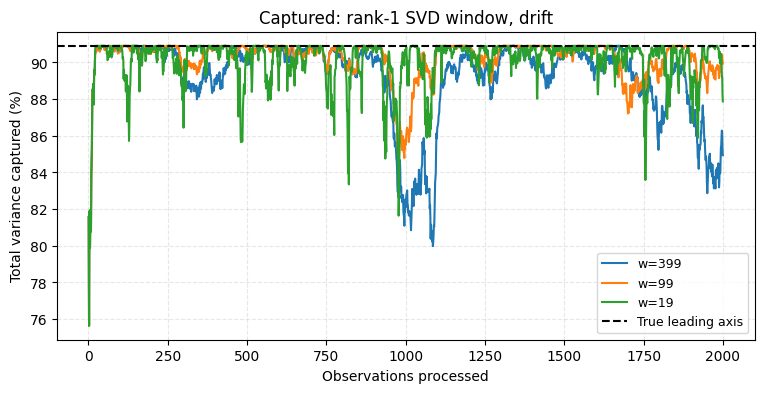

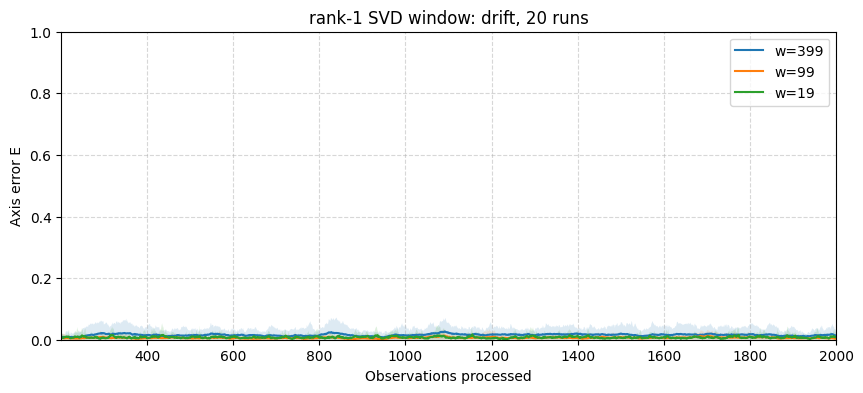

In [52]:
ut.show_plots(single['svd', 'drift'], results['svd', 'drift'], streams['drift'][seed][1], 'drift',
              settings_for['drift'], 'rank-1 SVD window', window_label)

#### Repeated-run measurements

In [53]:
ut.show_repeated_measurements(results['svd', 'drift'], 'drift', settings_for['drift'], window_label)

| Method | Mean E | SD of run means | Mean temporal SD |
| --- | --- | --- | --- |
| w=399 | 0.01566 | 0.00655 | 0.01871 |
| w=99 | 0.00602 | 0.00175 | 0.00770 |
| w=19 | 0.00764 | 0.00097 | 0.01121 |


## 3. Sliding-window PCA (TW-API)

### Theory: approximated power iteration on a window

The rank-1 SVD window of Section 2 has a weakness in the downdate, that is, when an old sample leaves the window.

- When a sample $x$ **enters**, the method keeps only the part of it along the current direction $q$ (rank 1): the part perpendicular to $q$ is thrown away.
- When the same sample **leaves**, $w$ steps later, it has to be removed. But the method does not remember what it stored for that sample: it removes $x$ again, starting from the direction it has **now**.

If the direction has not moved in the meantime, the two operations cancel. If it has moved, they do not. For example, if $x$ entered when the estimate pointed at $0^\circ$ and leaves when it points at $60^\circ$, the part removed at $60^\circ$ is not the part that was stored at $0^\circ$. The window then contains a small leftover that does not correspond to any of its samples. With forgetting this would not matter, because old information is discounted at every step and the leftover fades away; in a window nothing is discounted, so the leftover stays. This is the persistent error after the abrupt change studied in Section 5.

An alternative is to retain a compressed coordinate for each sample in the window and use that coordinate when the sample leaves. TW-API follows this approach, maintaining an approximate compressed cross-correlation matrix whose downdate uses the departing sample's stored coordinate rather than only its projection onto the current direction.

The subspace-tracking literature has a method that does this: the truncated-window approximated power iteration (TW-API) of Badeau, David and Richard (2005, Table II), which stores the coordinate of each sample at the moment it enters. `tw_api_pca` implements it for one direction and real data.

**Idea.**

The ideal tracker performs one power iteration per observation on the window matrix,

$$q_n=\frac{C_n\,q_{n-1}}{\lVert C_n\,q_{n-1}\rVert},\qquad C_n=\beta C_{n-1}+x_nx_n^\top-\beta^w x_{n-w}x_{n-w}^\top .$$

In this notebook $\beta=1$, the plain window, so all powers of $\beta$ below are equal to one.

TW-API never forms $C_n$. It assumes that the direction changes little in one step ($q_n\approx q_{n-1}\theta_n$, with $\theta_n$ close to one) and turns the power iteration into a recursion with a gain, as in RLS.

**One step, for $r=1$.**

State: the direction $q$; a scalar $z\approx 1/(q^\top S q)$, the inverse energy of the window along $q$; the buffer of the window; and, for each stored sample, its **coordinate $\hat v$ at the time it entered**.

1. Coordinates: $y=q^\top x_n$ for the entering sample and $v=q^\top x_{n-w}$ for the leaving one.
2. Perpendicular parts: $e_{\text{new}}=x_n-y\,q$ and $e_{\text{old}}=x_{n-w}-v\,q$.
3. Gains, from the $2\times2$ system of the paper solved in closed form:
$$g_{\text{new}}=\frac{z\,y}{D},\qquad g_{\text{old}}=-\frac{\beta^w z\,\hat v}{D},\qquad D=\beta+z\,y^2-\beta^w z\,\hat v\,v .$$
4. Direction: $q\leftarrow(q+g_{\text{new}}e_{\text{new}}+g_{\text{old}}e_{\text{old}})\,\theta$, where $\theta=(1+\lVert g_{\text{new}}e_{\text{new}}+g_{\text{old}}e_{\text{old}}\rVert^2)^{-1/2}$ restores unit length exactly.
5. Energy: $z\leftarrow z\,(1-g_{\text{new}}\,y-g_{\text{old}}\,v)/\beta$ (matrix inversion lemma).
6. Stored coordinates follow the basis: $\hat v\leftarrow\theta\,\hat v$.

The leaving sample enters the gain through its stored coordinate $\hat v$ and the residual through its current coordinate $v$: what is removed is consistent with what was added.

### Stationary data

In [54]:
single['twapi', 'stationary'] = single_run(tw_api_pca, window_sizes, streams['stationary'][seed])

#### Single-run measurements

In [55]:
ut.show_single_run(single['twapi', 'stationary'], 'stationary', settings_for['stationary'], window_label)

| Method | Mean error after warm-up | Temporal error SD |
| --- | --- | --- |
| w=399 | 0.00038 | 0.00050 |
| w=99 | 0.00125 | 0.00206 |
| w=19 | 0.00610 | 0.00931 |


#### Repeat with 20 seeds

In [56]:
results['twapi', 'stationary'] = repeat_runs(tw_api_pca, window_sizes, streams['stationary'], 'stationary', settings_for['stationary'],
                                   'Sliding-window PCA (TW-API)', 'window_size')

Saved Sliding-window PCA (TW-API), stationary, alpha= to C:\Users\mesie\OneDrive\Desktop\TESI\online_pca_thesis\results\sliding_window\sliding_window_results.csv


Saved Sliding-window PCA (TW-API), stationary, alpha= to C:\Users\mesie\OneDrive\Desktop\TESI\online_pca_thesis\results\sliding_window\sliding_window_results.csv


Saved Sliding-window PCA (TW-API), stationary, alpha= to C:\Users\mesie\OneDrive\Desktop\TESI\online_pca_thesis\results\sliding_window\sliding_window_results.csv


#### Computational cost

In [57]:
ut.show_cost(results['twapi', 'stationary'], window_label)

| Method | Mean seconds | Shortest seconds | Longest seconds | SD seconds |
| --- | --- | --- | --- | --- |
| w=399 | 0.0196815650066128 | 0.019330799987073988 | 0.02007149998098612 | 0.00021513398051988556 |
| w=99 | 0.022045454996987245 | 0.019499899994116277 | 0.028520599997136742 | 0.002026721344038404 |
| w=19 | 0.022172585001681 | 0.019439099996816367 | 0.028536800004076213 | 0.0021989633977044865 |


#### Repeated-run plot

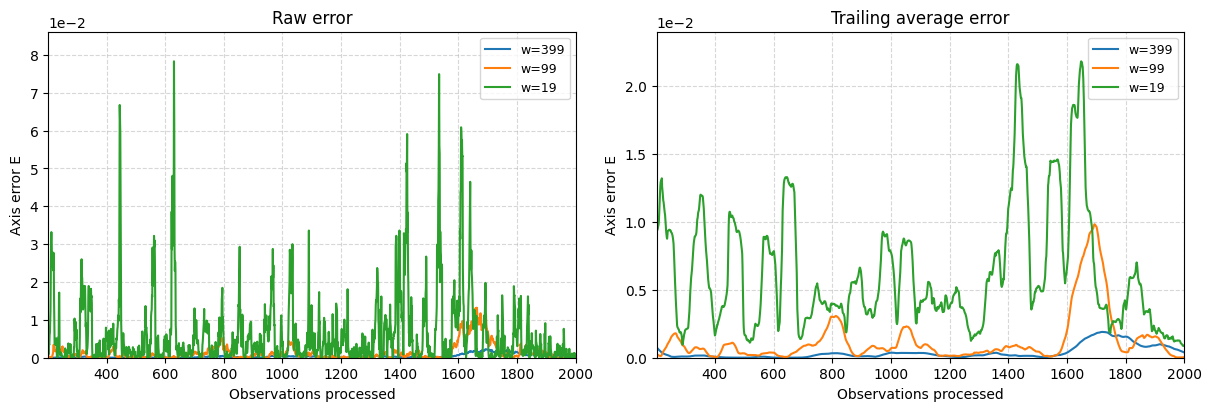

w=399 cumulative error from observation 1: 1.449377389938753
w=99 cumulative error from observation 1: 2.957369056469243
w=19 cumulative error from observation 1: 12.289930412120038


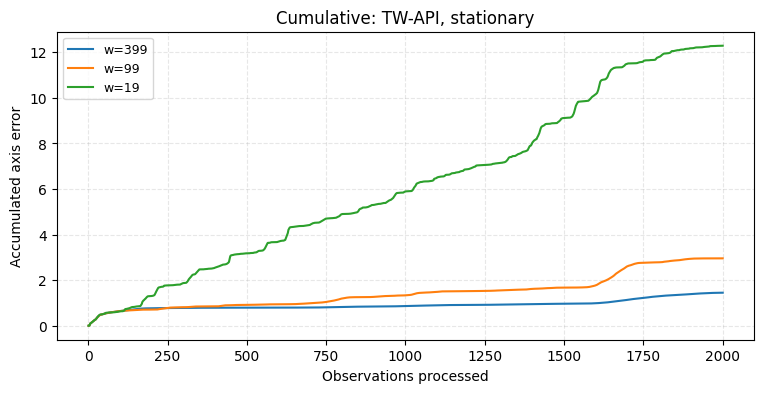

w=399 stationary angle SD (degrees): 0.7994256225821403
w=99 stationary angle SD (degrees): 1.8529478858033446
w=19 stationary angle SD (degrees): 4.3998596179694145


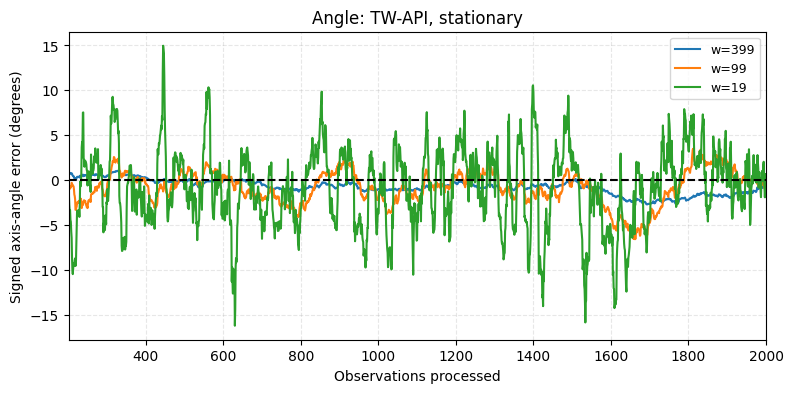

w=399 mean captured variance after warm-up (%): 90.87827004815746
w=99 mean captured variance after warm-up (%): 90.8068533399864
w=19 mean captured variance after warm-up (%): 90.40979578840992


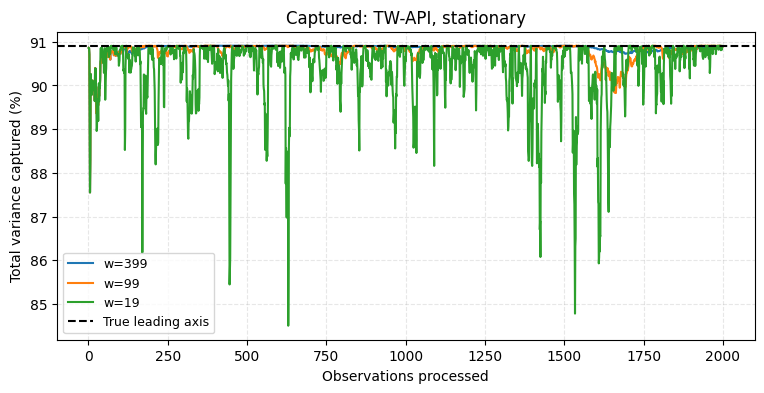

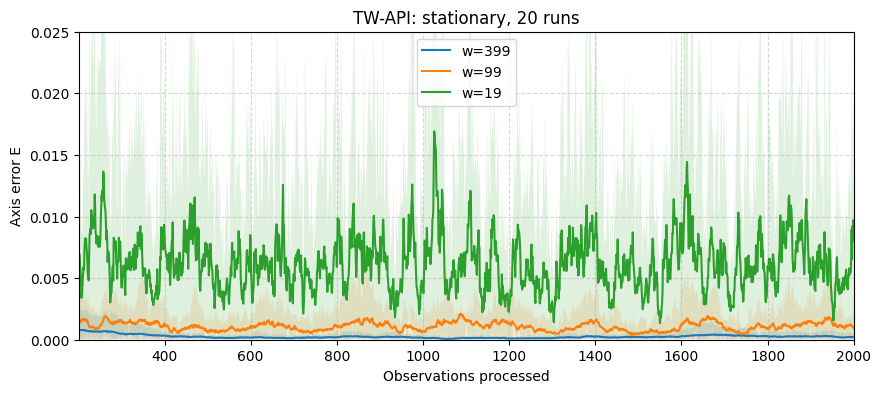

In [58]:
ut.show_plots(single['twapi', 'stationary'], results['twapi', 'stationary'], streams['stationary'][seed][1], 'stationary',
              settings_for['stationary'], 'TW-API', window_label)

#### Repeated-run measurements

In [59]:
ut.show_repeated_measurements(results['twapi', 'stationary'], 'stationary', settings_for['stationary'], window_label)

| Method | Mean E | SD of run means | Mean temporal SD |
| --- | --- | --- | --- |
| w=399 | 0.00025 | 0.00015 | 0.00031 |
| w=99 | 0.00109 | 0.00040 | 0.00147 |
| w=19 | 0.00619 | 0.00088 | 0.00930 |


### Abrupt-change data

In [60]:
single['twapi', 'abrupt'] = single_run(tw_api_pca, window_sizes, streams['abrupt'][seed])

#### Single-run measurements

In [61]:
ut.show_single_run(single['twapi', 'abrupt'], 'abrupt', settings_for['abrupt'], window_label)

| Method | Pre-change mean E | Post-change mean E | Final-segment mean E | Recovery delay |
| --- | --- | --- | --- | --- |
| w=399 | 0.00012 | 0.17571 | 0.00090 | 395.0 |
| w=99 | 0.00079 | 0.04479 | 0.00077 | 125.0 |
| w=19 | 0.00574 | 0.01455 | 0.00230 | 60.0 |


#### Repeat with 20 seeds

In [62]:
results['twapi', 'abrupt'] = repeat_runs(tw_api_pca, window_sizes, streams['abrupt'], 'abrupt', settings_for['abrupt'],
                                   'Sliding-window PCA (TW-API)', 'window_size')

Saved Sliding-window PCA (TW-API), abrupt, alpha= to C:\Users\mesie\OneDrive\Desktop\TESI\online_pca_thesis\results\sliding_window\sliding_window_results.csv


Saved Sliding-window PCA (TW-API), abrupt, alpha= to C:\Users\mesie\OneDrive\Desktop\TESI\online_pca_thesis\results\sliding_window\sliding_window_results.csv


Saved Sliding-window PCA (TW-API), abrupt, alpha= to C:\Users\mesie\OneDrive\Desktop\TESI\online_pca_thesis\results\sliding_window\sliding_window_results.csv


#### Computational cost

In [63]:
ut.show_cost(results['twapi', 'abrupt'], window_label)

| Method | Mean seconds | Shortest seconds | Longest seconds | SD seconds |
| --- | --- | --- | --- | --- |
| w=399 | 0.02185105999233201 | 0.017675099952612072 | 0.02449560002423823 | 0.0012805374113824632 |
| w=99 | 0.021116899995831773 | 0.01886240002932027 | 0.029509499960113317 | 0.002441326249915811 |
| w=19 | 0.02293005500396248 | 0.01983410003595054 | 0.02733399998396635 | 0.0017696043897973918 |


#### Repeated-run plot

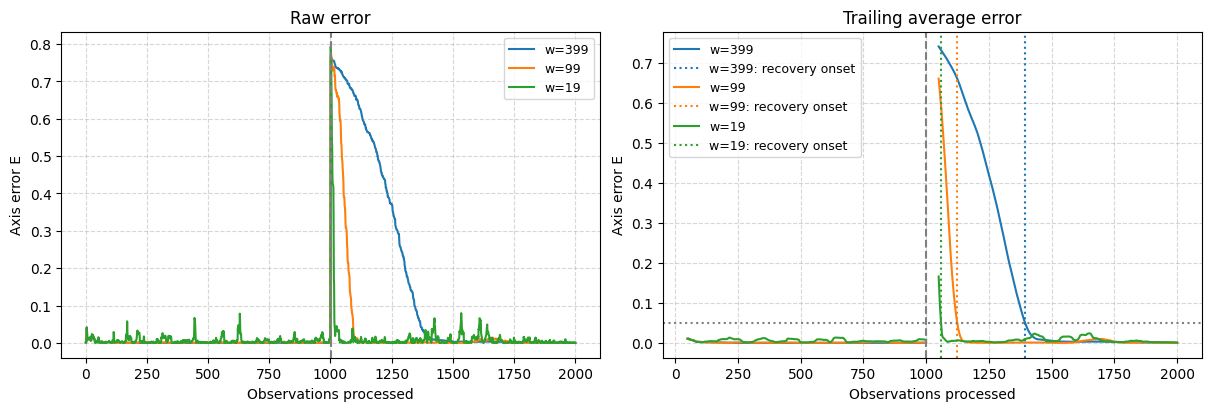

w=399 cumulative error from observation 1: 176.57806287788517
w=99 cumulative error from observation 1: 46.124621374949825
w=19 cumulative error from observation 1: 20.442571206605454


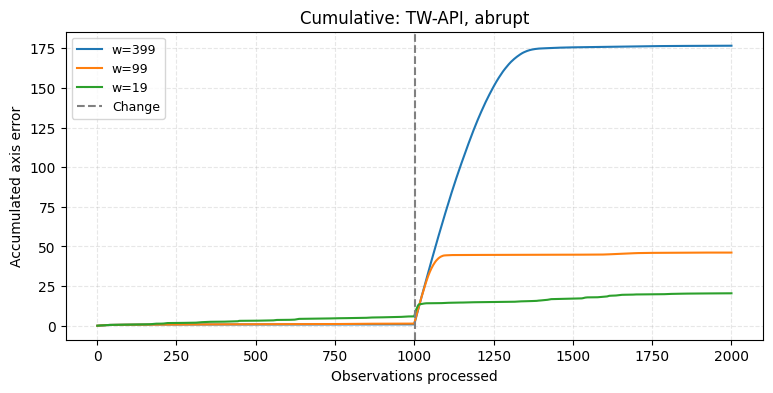

w=399 stationary angle SD (degrees): 0.575454275380405
w=99 stationary angle SD (degrees): 1.4784233158340252
w=19 stationary angle SD (degrees): 4.2538892193365605


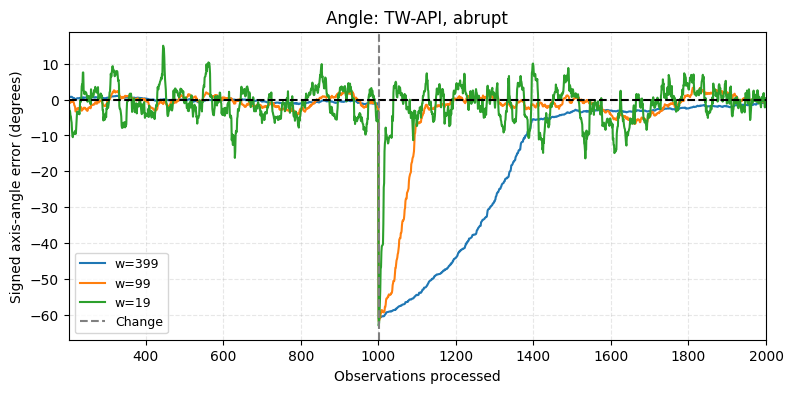

w=399 mean captured variance after warm-up (%): 82.91787525325081
w=99 mean captured variance after warm-up (%): 88.8447055073282
w=19 mean captured variance after warm-up (%): 90.03922120684243


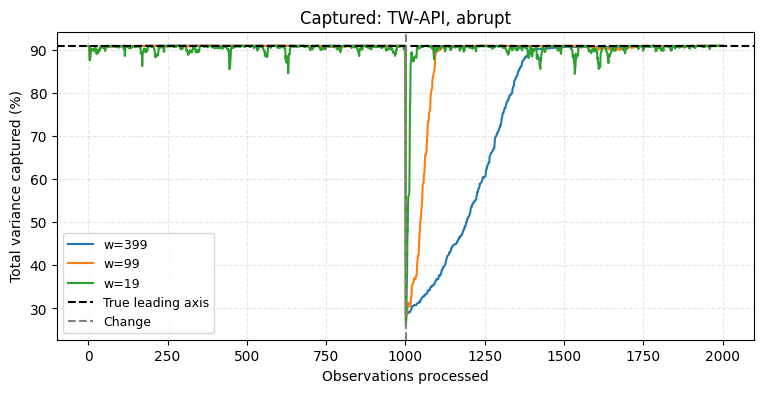

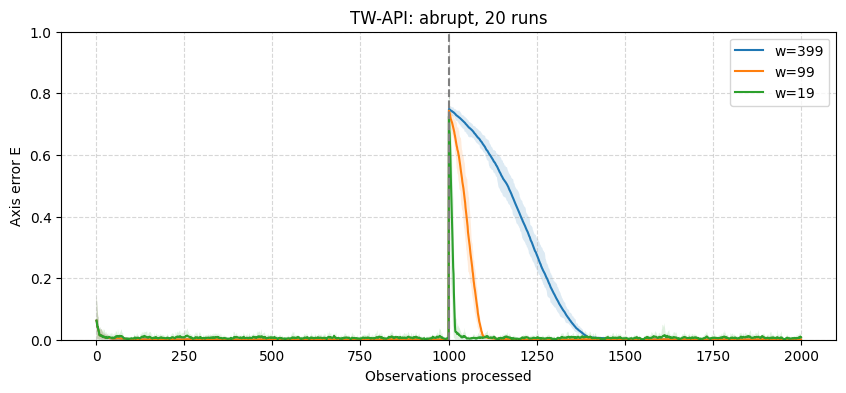

In [64]:
ut.show_plots(single['twapi', 'abrupt'], results['twapi', 'abrupt'], streams['abrupt'][seed][1], 'abrupt',
              settings_for['abrupt'], 'TW-API', window_label)

#### Repeated-run measurements

In [65]:
ut.show_repeated_measurements(results['twapi', 'abrupt'], 'abrupt', settings_for['abrupt'], window_label)

| Method | Pre-change E: mean +/- SD | Post-change E: mean +/- SD | Final E: mean +/- SD | Recovered runs | Median delay |
| --- | --- | --- | --- | --- | --- |
| w=399 | 0.00029 +/- 0.00020 | 0.15720 +/- 0.01031 | 0.00027 +/- 0.00030 | 20/20 | 376.0 |
| w=99 | 0.00110 +/- 0.00047 | 0.03971 +/- 0.00544 | 0.00123 +/- 0.00125 | 20/20 | 120.5 |
| w=19 | 0.00623 +/- 0.00125 | 0.01330 +/- 0.00293 | 0.00643 +/- 0.00286 | 20/20 | 58.5 |


### Smooth rotation data

In [66]:
single['twapi', 'rotation'] = single_run(tw_api_pca, window_sizes, streams['rotation'][seed])

#### Single-run measurements

In [67]:
ut.show_single_run(single['twapi', 'rotation'], 'rotation', settings_for['rotation'], window_label)

| Method | Mean error after warm-up | Temporal error SD |
| --- | --- | --- |
| w=399 | 0.05213 | 0.01340 |
| w=99 | 0.00604 | 0.00548 |
| w=19 | 0.00701 | 0.01089 |


#### Repeat with 20 seeds

In [68]:
results['twapi', 'rotation'] = repeat_runs(tw_api_pca, window_sizes, streams['rotation'], 'rotation', settings_for['rotation'],
                                   'Sliding-window PCA (TW-API)', 'window_size')

Saved Sliding-window PCA (TW-API), rotation, alpha= to C:\Users\mesie\OneDrive\Desktop\TESI\online_pca_thesis\results\sliding_window\sliding_window_rotation_results_omega=0.001_dt=1.csv


Saved Sliding-window PCA (TW-API), rotation, alpha= to C:\Users\mesie\OneDrive\Desktop\TESI\online_pca_thesis\results\sliding_window\sliding_window_rotation_results_omega=0.001_dt=1.csv


Saved Sliding-window PCA (TW-API), rotation, alpha= to C:\Users\mesie\OneDrive\Desktop\TESI\online_pca_thesis\results\sliding_window\sliding_window_rotation_results_omega=0.001_dt=1.csv


#### Computational cost

In [69]:
ut.show_cost(results['twapi', 'rotation'], window_label)

| Method | Mean seconds | Shortest seconds | Longest seconds | SD seconds |
| --- | --- | --- | --- | --- |
| w=399 | 0.022065080000902525 | 0.01888150000013411 | 0.02365550003014505 | 0.0013983130893303283 |
| w=99 | 0.0226927049952792 | 0.01940029999241233 | 0.03004099999088794 | 0.0022294673597703504 |
| w=19 | 0.02201728000654839 | 0.0197139999945648 | 0.024030599975958467 | 0.0015788033148309356 |


#### Repeated-run plot

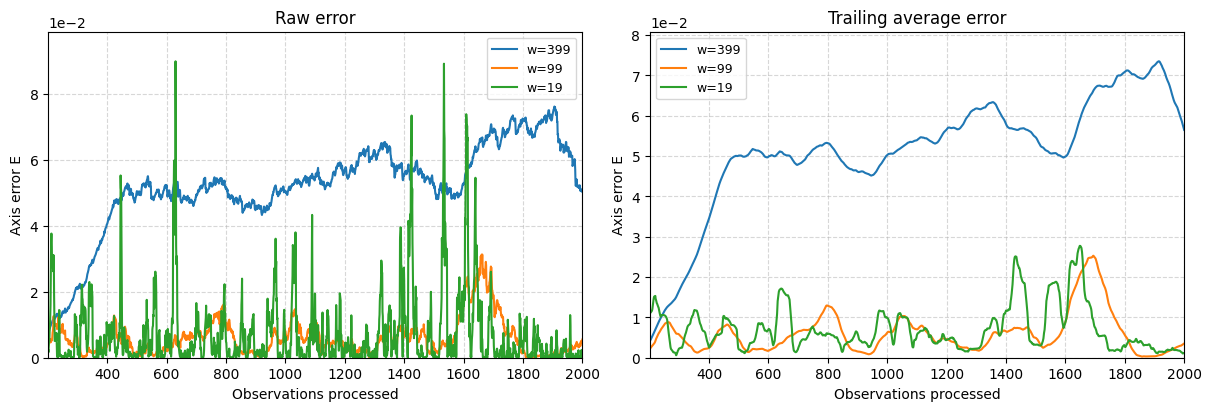

w=399 cumulative error from observation 1: 94.49846839798437
w=99 cumulative error from observation 1: 11.45366030958085
w=19 cumulative error from observation 1: 13.96337568449878


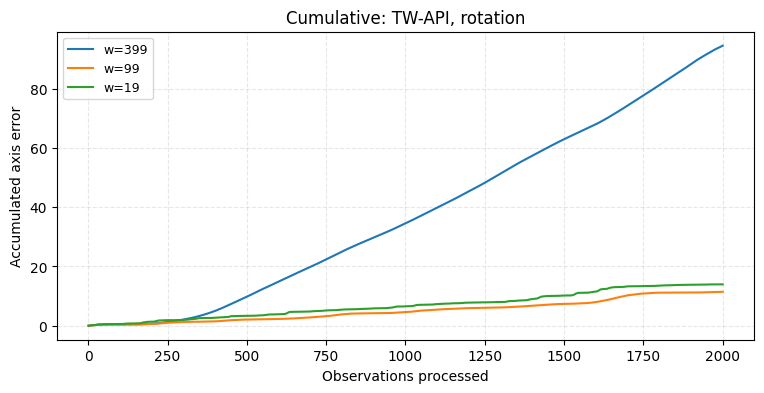

w=399 tracking angle-error SD (degrees): 2.0001699222319766
w=99 tracking angle-error SD (degrees): 1.8995726494992322
w=19 tracking angle-error SD (degrees): 4.4382980669957375


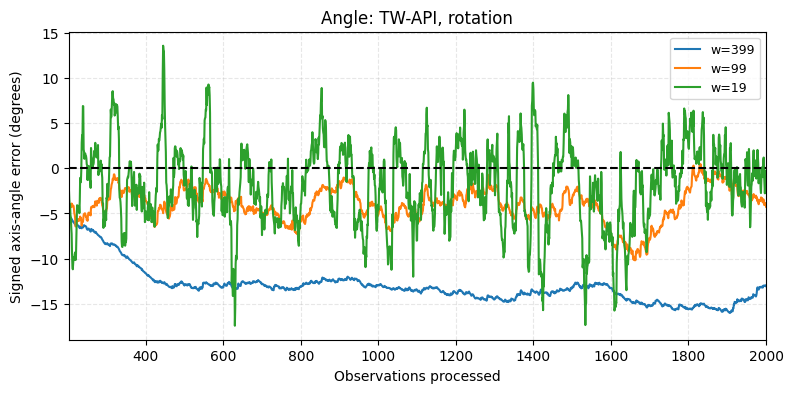

w=399 mean captured variance after warm-up (%): 86.64392717687282
w=99 mean captured variance after warm-up (%): 90.41455496187238
w=19 mean captured variance after warm-up (%): 90.3351900448528


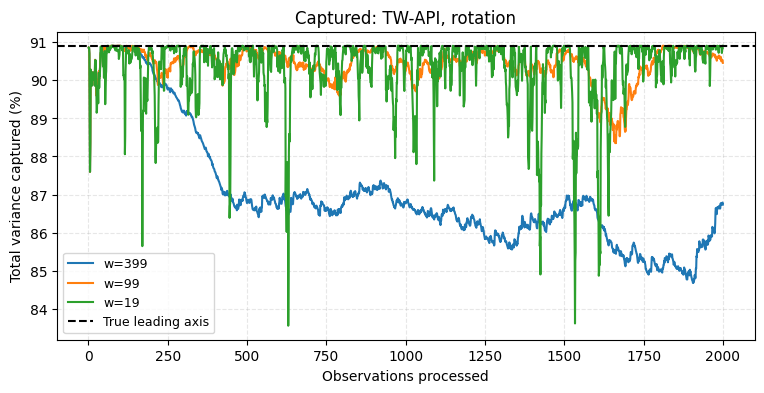

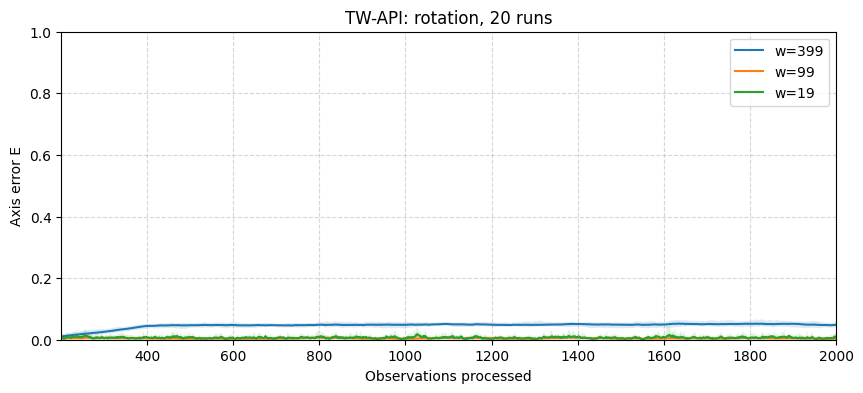

In [70]:
ut.show_plots(single['twapi', 'rotation'], results['twapi', 'rotation'], streams['rotation'][seed][1], 'rotation',
              settings_for['rotation'], 'TW-API', window_label)

#### Repeated-run measurements

In [71]:
ut.show_repeated_measurements(results['twapi', 'rotation'], 'rotation', settings_for['rotation'], window_label)

| Method | Mean E | SD of run means | Mean temporal SD |
| --- | --- | --- | --- |
| w=399 | 0.04649 | 0.00298 | 0.01002 |
| w=99 | 0.00446 | 0.00112 | 0.00410 |
| w=19 | 0.00657 | 0.00107 | 0.00992 |


### Random drift data

In [72]:
single['twapi', 'drift'] = single_run(tw_api_pca, window_sizes, streams['drift'][seed])

#### Single-run measurements

In [73]:
ut.show_single_run(single['twapi', 'drift'], 'drift', settings_for['drift'], window_label)

| Method | Mean error after warm-up | Temporal error SD |
| --- | --- | --- |
| w=399 | 0.02011 | 0.02388 |
| w=99 | 0.00640 | 0.00973 |
| w=19 | 0.00799 | 0.01178 |


#### Repeat with 20 seeds

In [74]:
results['twapi', 'drift'] = repeat_runs(tw_api_pca, window_sizes, streams['drift'], 'drift', settings_for['drift'],
                                   'Sliding-window PCA (TW-API)', 'window_size')

Saved Sliding-window PCA (TW-API), drift, alpha= to C:\Users\mesie\OneDrive\Desktop\TESI\online_pca_thesis\results\sliding_window\sliding_window_drift_results_Q=0.0001_dt=1.csv


Saved Sliding-window PCA (TW-API), drift, alpha= to C:\Users\mesie\OneDrive\Desktop\TESI\online_pca_thesis\results\sliding_window\sliding_window_drift_results_Q=0.0001_dt=1.csv


Saved Sliding-window PCA (TW-API), drift, alpha= to C:\Users\mesie\OneDrive\Desktop\TESI\online_pca_thesis\results\sliding_window\sliding_window_drift_results_Q=0.0001_dt=1.csv


#### Computational cost

In [75]:
ut.show_cost(results['twapi', 'drift'], window_label)

| Method | Mean seconds | Shortest seconds | Longest seconds | SD seconds |
| --- | --- | --- | --- | --- |
| w=399 | 0.021862990004592575 | 0.018449999974109232 | 0.0230967000243254 | 0.0012820901514037566 |
| w=99 | 0.022118650004267694 | 0.019510399957653135 | 0.029499399999622256 | 0.0027694679780769804 |
| w=19 | 0.02195410000276752 | 0.02031699998769909 | 0.026419500005431473 | 0.0016159627234781104 |


#### Repeated-run plot

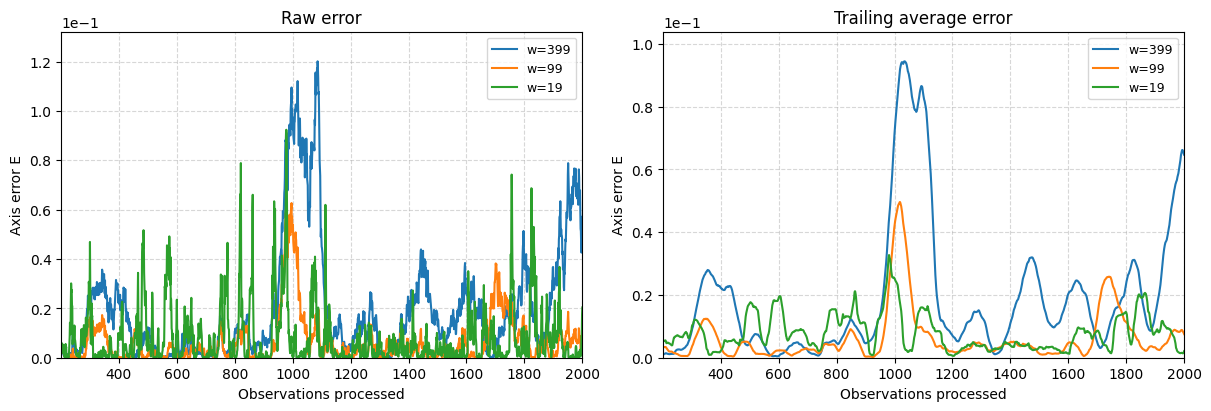

w=399 cumulative error from observation 1: 37.61753169348417
w=99 cumulative error from observation 1: 13.072953233205057
w=19 cumulative error from observation 1: 16.62418507814548


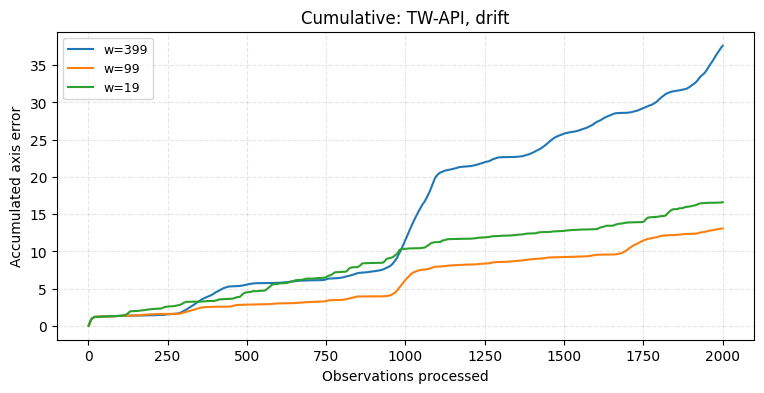

w=399 tracking angle-error SD (degrees): 7.072929493935803
w=99 tracking angle-error SD (degrees): 4.232575044401158
w=19 tracking angle-error SD (degrees): 5.016035310245392


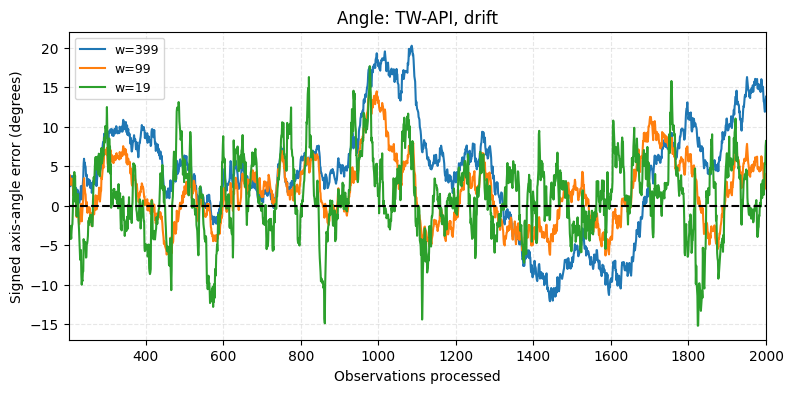

w=399 mean captured variance after warm-up (%): 89.26398530307947
w=99 mean captured variance after warm-up (%): 90.38539153352535
w=19 mean captured variance after warm-up (%): 90.25565725544439


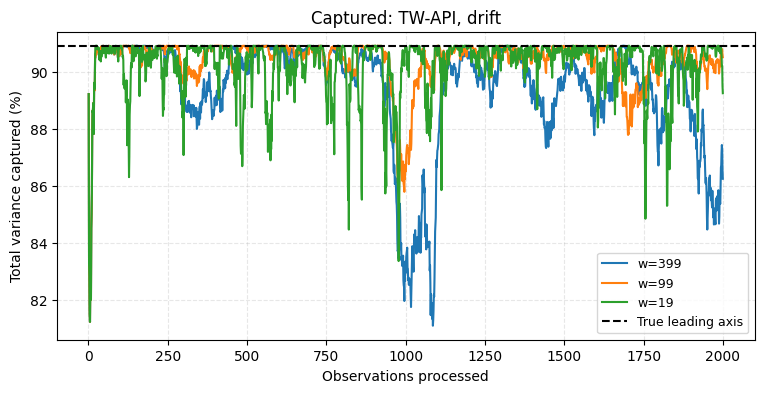

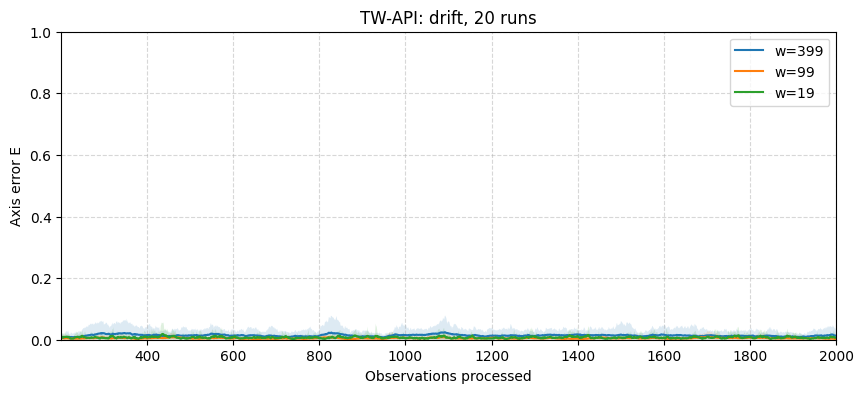

In [76]:
ut.show_plots(single['twapi', 'drift'], results['twapi', 'drift'], streams['drift'][seed][1], 'drift',
              settings_for['drift'], 'TW-API', window_label)

#### Repeated-run measurements

In [77]:
ut.show_repeated_measurements(results['twapi', 'drift'], 'drift', settings_for['drift'], window_label)

| Method | Mean E | SD of run means | Mean temporal SD |
| --- | --- | --- | --- |
| w=399 | 0.01394 | 0.00483 | 0.01730 |
| w=99 | 0.00482 | 0.00086 | 0.00619 |
| w=19 | 0.00711 | 0.00101 | 0.01051 |


# Part 2: analysis

# 4. Correctness and numerical drift

### Agreement on one stream

All exact versions must give the same matrix and the same axis as the naive recomputation, up to rounding. The approximate versions (rank-1 SVD, TW-API) are shown for comparison.

In [78]:
w = 99
naive_q, naive_C = sliding_window_pca(X_abrupt, w)
versions = {
    'Covariance update/downdate': sliding_window_cov_pca(X_abrupt, w),
    'Covariance update/downdate, rebuild every 500': sliding_window_cov_pca(X_abrupt, w, recompute_every=500),
    'SVD update/downdate, rank 2': sliding_window_svd_pca(X_abrupt, w, rank=2),
    'SVD update/downdate, rank 1 (approximate)': sliding_window_svd_pca(X_abrupt, w, rank=1),
}
rows = []
for label, (directions, C) in versions.items():
    rows.append([label, f'{np.abs(C - naive_C).max():.2e}', f'{axis_error(directions, naive_q).max():.2e}'])
tw_q, tw_eigenvalue = tw_api_pca(X_abrupt, w)
rows.append(['TW-API (approximate)', f'leading eigenvalue {tw_eigenvalue:.4f} vs {np.linalg.eigvalsh(naive_C)[-1]:.4f}',
             f'{axis_error(tw_q, naive_q).max():.2e}'])
ut.show_table(['Version (w=99, abrupt stream)', 'max |C - C_naive| at the end', 'max axis gap to naive over time'], rows)

| Version (w=99, abrupt stream) | max |C - C_naive| at the end | max axis gap to naive over time |
| --- | --- | --- |
| Covariance update/downdate | 5.55e-15 | 8.88e-16 |
| Covariance update/downdate, rebuild every 500 | 0.00e+00 | 8.88e-16 |
| SVD update/downdate, rank 2 | 1.77e-13 | 8.88e-16 |
| SVD update/downdate, rank 1 (approximate) | 1.71e+00 | 9.96e-02 |
| TW-API (approximate) | leading eigenvalue 5.7571 vs 5.7582 | 8.53e-02 |


The exact versions agree with the naive window to rounding precision. The two approximate versions differ for a different reason each: truncation for rank-1 SVD, the approximated power iteration for TW-API. Their largest gaps occur during the transition after the change (Section 5).

### Rounding drift

$S_n$ is obtained by adding and subtracting the same terms many times. In floating point, $(S+xx^\top)-xx^\top$ need not be exactly $S$, and the rounding errors accumulate. A naive recomputation has no memory of past rounding errors, so it does not drift.

**Ordinary data.**


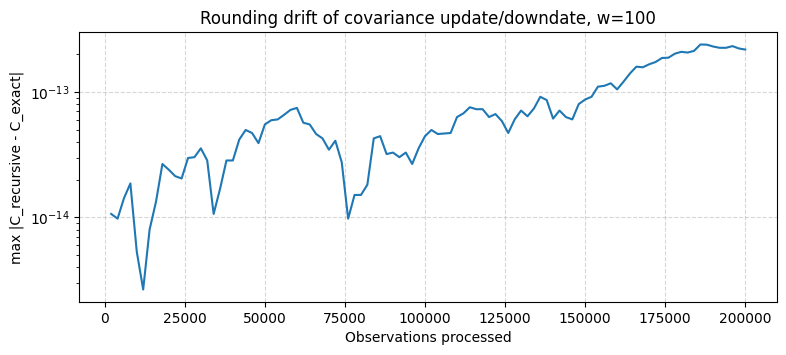

Largest drift over 200000 steps: 2.4e-13  (entries of C are of order 5.0)


In [79]:
# One long stationary stream; compare the recursive sum with an exact rebuild at checkpoints
long_n = 200_000
w = 100
X_long, _, _ = generate_stationary(1, n_samples=long_n, lam1=lam1, lam2=lam2, theta0=theta0)

S = np.zeros((2, 2))
checkpoints, drift = [], []
for index in range(long_n):
    S += np.outer(X_long[index], X_long[index])
    if index >= w:
        S -= np.outer(X_long[index - w], X_long[index - w])
    if (index + 1) % 2000 == 0:
        window = X_long[index + 1 - w:index + 1]
        checkpoints.append(index + 1)
        drift.append(np.abs(S / w - window.T @ window / w).max())

fig, ax = plt.subplots(figsize=(9, 3.5))
ax.semilogy(checkpoints, drift)
ax.set_xlabel('Observations processed')
ax.set_ylabel('max |C_recursive - C_exact|')
ax.set_title('Rounding drift of covariance update/downdate, w=100')
ax.grid(True, linestyle='--', alpha=0.5)
plt.show()
print(f'Largest drift over {long_n} steps: {max(drift):.1e}  (entries of C are of order {lam1})')

The error stays at the level of machine precision times the size of the entries. On this kind of data the drift is irrelevant.

**One very large observation.**

Rounding error is relative to the size of the numbers involved. If a single observation of size $10^8$ (over the significant digits retained by a computer) enters the window, $S$ becomes of order $10^{16}$ and its small entries are stored with an absolute error of order $10^{16}\cdot 10^{-16}=1$. When that observation leaves, the large part cancels, but the absolute error stays, and it is now large compared with $\lambda_1=5$. The recursion has no way of noticing it: the error is permanent. A periodic rebuild from the buffer removes it.

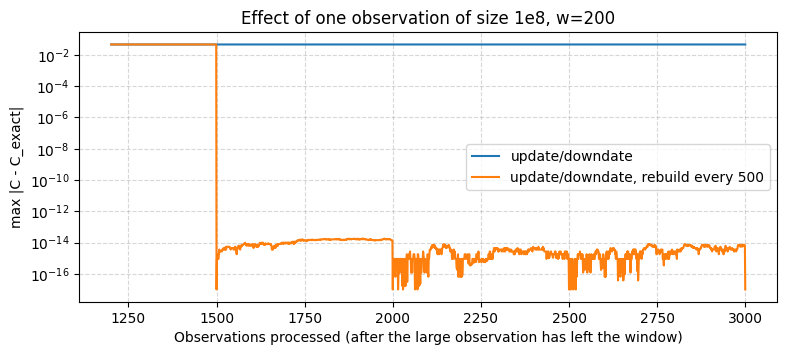

| Version | C at the last step |
| --- | --- |
| exact (naive) | [[5.07, -0.101], [-0.101, 0.481]] |
| update/downdate | [[5.115, -0.085], [-0.085, 0.48]] |
| rebuild every 500 | [[5.07, -0.101], [-0.101, 0.481]] |


In [80]:
X_outlier, _, truth_outlier = generate_stationary(0, n_samples=3000, lam1=lam1, lam2=lam2, theta0=theta0)
X_outlier = X_outlier.copy()
outlier_step = 1000
X_outlier[outlier_step] = [1e8, 3e7]
w = 200

def covariance_trace(X, w, recompute_every=None):
    # entries of C after every step, for plotting
    S = np.zeros((2, 2))
    out = np.zeros((len(X), 2, 2))
    for index in range(len(X)):
        S += np.outer(X[index], X[index])
        if index >= w:
            S -= np.outer(X[index - w], X[index - w])
        count = min(index + 1, w)
        if recompute_every is not None and (index + 1) % recompute_every == 0:
            window = X[index + 1 - count:index + 1]
            S = window.T @ window
        out[index] = S / count
    return out

exact = np.array([X_outlier[max(0, i + 1 - w):i + 1].T @ X_outlier[max(0, i + 1 - w):i + 1] / min(i + 1, w)
                  for i in range(len(X_outlier))])
recursive = covariance_trace(X_outlier, w)
rebuilt = covariance_trace(X_outlier, w, recompute_every=500)

after_exit = np.arange(outlier_step + w, len(X_outlier))
fig, ax = plt.subplots(figsize=(9, 3.5))
ax.semilogy(after_exit + 1, np.abs(recursive - exact).max(axis=(1, 2))[after_exit] + 1e-17, label='update/downdate')
ax.semilogy(after_exit + 1, np.abs(rebuilt - exact).max(axis=(1, 2))[after_exit] + 1e-17, label='update/downdate, rebuild every 500')
ax.set_xlabel('Observations processed (after the large observation has left the window)')
ax.set_ylabel('max |C - C_exact|')
ax.set_title('Effect of one observation of size 1e8, w=200')
ax.grid(True, linestyle='--', alpha=0.5)
ax.legend()
plt.show()

rows = []
for label, trace in [('exact (naive)', exact), ('update/downdate', recursive), ('rebuild every 500', rebuilt)]:
    rows.append([label, np.round(trace[-1], 3).tolist()])
ut.show_table(['Version', 'C at the last step'], rows)

This is why `sliding_window_cov_pca` has the `recompute_every` option. A rebuild costs $O(w)$, so rebuilding every $k\geq w$ steps keeps the average cost per step $O(1)$. In the synthetic regimes of this thesis the data are Gaussian with variances of order one, so no rebuild is needed. The SVD version has the same issue in principle, because a downdate is also a subtraction.

# 5. Truncated downdate and consistent downdate

The rank-1 SVD window (Section 2) keeps one eigenpair $(u,s^2)$. Each sample that enters is projected: the part $\rho$ perpendicular to $u$ is used to rotate $u$, and then the second eigenvalue is discarded. When the same sample leaves, $w$ steps later, it is subtracted with its full **current** projection. The bookkeeping would be consistent only if $u$ had not moved in between and nothing had been discarded.

TW-API (Section 3) also tracks one direction, but removes the leaving sample through the coordinate $\hat v$ **stored when it entered**: what is removed is consistent with what was added.

Three things can be measured:

- the retained eigenvalue of the rank-1 SVD window against the largest eigenvalue of the exact window;
- the distance of each approximate method from the exact window direction over time;
- the mean error around the abrupt change, across seeds;
- the signed angular error in the abrupt, rotation and drift regimes.

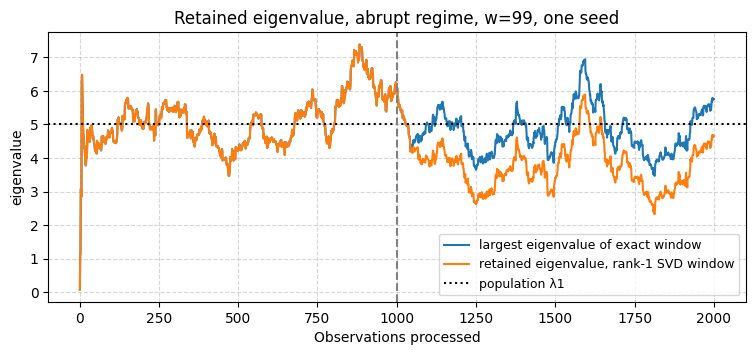

In [81]:
w = 99

def rank1_window_trace(X, w):
    U = np.eye(2)[:, :1]
    s2 = np.zeros(1)
    retained = np.zeros(len(X))
    for index in range(len(X)):
        U, s2 = svd_rank_one_modify(U, s2, X[index], +1, 1)
        if index >= w:
            U, s2 = svd_rank_one_modify(U, s2, X[index - w], -1, 1)
            s2 = np.maximum(s2, 0.0)
        retained[index] = s2[0] / min(index + 1, w)
    return retained

retained = rank1_window_trace(X_abrupt, w)
exact_largest = np.array([np.linalg.eigvalsh(X_abrupt[max(0, i + 1 - w):i + 1].T @ X_abrupt[max(0, i + 1 - w):i + 1]
                                             / min(i + 1, w))[-1] for i in range(n_samples)])

fig, ax = plt.subplots(figsize=(9, 3.5))
ax.plot(steps, exact_largest, label='largest eigenvalue of exact window')
ax.plot(steps, retained, label='retained eigenvalue, rank-1 SVD window')
ax.axhline(lam1, color='black', linestyle=':', label='population λ1')
ax.axvline(switch_step + 1, color='gray', linestyle='--')
ax.set_xlabel('Observations processed')
ax.set_ylabel('eigenvalue')
ax.set_title('Retained eigenvalue, abrupt regime, w=99, one seed')
ax.grid(True, linestyle='--', alpha=0.5)
ax.legend(fontsize=9)
plt.show()

Before the change the two curves are identical: while the direction does not move, the truncation costs nothing. After the change the retained eigenvalue of the rank-1 SVD window drops below that of the exact window (by about $1$) and never comes back, even when the window contains only new data. The rank-1 SVD window removes more than it should when old samples leave, and the error is permanent.

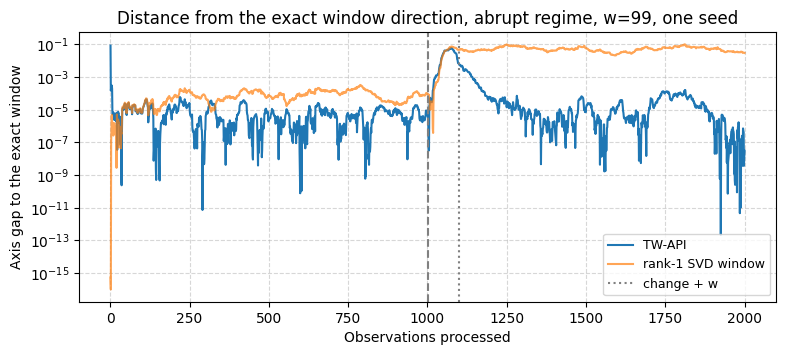

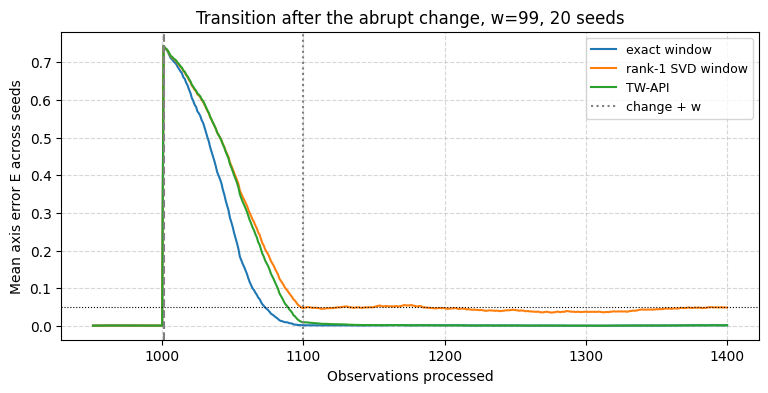

In [82]:
exact_q = single['exact', 'abrupt'][w][0]
fig, ax = plt.subplots(figsize=(9, 3.5))
ax.semilogy(steps, axis_error(single['twapi', 'abrupt'][w][0], exact_q) + 1e-16, label='TW-API')
ax.semilogy(steps, axis_error(single['svd', 'abrupt'][w][0], exact_q) + 1e-16, label='rank-1 SVD window', alpha=0.7)
ax.axvline(switch_step + 1, color='gray', linestyle='--')
ax.axvline(switch_step + w + 1, color='gray', linestyle=':', label='change + w')
ax.set_xlabel('Observations processed')
ax.set_ylabel('Axis gap to the exact window')
ax.set_title('Distance from the exact window direction, abrupt regime, w=99, one seed')
ax.grid(True, linestyle='--', alpha=0.5)
ax.legend(fontsize=9)
plt.show()

fig, ax = plt.subplots(figsize=(9, 4))
zoom = np.arange(switch_step - 50, switch_step + 400)
for key, label in [('exact', 'exact window'), ('svd', 'rank-1 SVD window'), ('twapi', 'TW-API')]:
    mean_error = results[key, 'abrupt'][w][0].mean(axis=0)
    ax.plot(zoom + 1, mean_error[zoom], label=label)
ax.axvline(switch_step + 1, color='gray', linestyle='--')
ax.axvline(switch_step + w + 1, color='gray', linestyle=':', label='change + w')
ax.axhline(recovery_threshold, color='black', linestyle=':', linewidth=0.8)
ax.set_xlabel('Observations processed')
ax.set_ylabel('Mean axis error E across seeds')
ax.set_title('Transition after the abrupt change, w=99, 20 seeds')
ax.grid(True, linestyle='--', alpha=0.5)
ax.legend(fontsize=9)
plt.show()

**Distance from the exact window direction.** Before the change both methods are practically on top of the exact window (gap of about $10^{-5}$ or less). At the change both move away from it (gap of about $0.05$–$0.1$). After *change + w*, when the old data have left the window, TW-API falls back to the exact window, while the rank-1 SVD window stays away from it until the end. The error of TW-API is temporary, that of the rank-1 SVD window permanent. (The spike at the very start is only the start-up, when the window is almost empty.)

**Transition after the change (20 seeds).** The exact window recovers first, and TW-API shortly after (one approximated power iteration per step lags a little behind the exact eigenvector); both reach the stationary level before *change + w*. The rank-1 SVD window stops at about $0.04$–$0.05$ and stays there, just below the recovery threshold: this is why it counts as "recovered" with the default threshold $0.05$ but not with $0.02$ (`04_sensitivity_analysis`, A1–A2).

In [83]:
# Error after the old samples have left the window: last 500 steps of the abrupt regime
window_versions = {'exact': 'exact window', 'svd': 'rank-1 SVD window', 'twapi': 'TW-API'}
rows = []
for w in window_sizes:
    rows.append([f'w={w}'] + [f"{results[key, 'abrupt'][w][0][:, -500:].mean():.5f}" for key in window_versions])
ut.show_table(['Abrupt, last 500 steps'] + list(window_versions.values()), rows)

| Abrupt, last 500 steps | exact window | rank-1 SVD window | TW-API |
| --- | --- | --- | --- |
| w=399 | 0.00032 | 0.04177 | 0.00064 |
| w=99 | 0.00120 | 0.04093 | 0.00109 |
| w=19 | 0.00733 | 0.01573 | 0.00631 |


### Rotation and drift

The measurements above use the abrupt regime. In smooth rotation and random drift the direction moves continuously, so the mismatch between what enters and what leaves the rank-1 SVD window is produced at every step, not only after one event. Its effect is measured with the **signed** angular error (estimated minus true angle), averaged over time for each seed:

- a mean signed angle that is different from zero, with the same sign in every seed, is a systematic lag;
- a larger spread of the per-seed means, without a common sign, is an error that follows the random direction of the drift.

For the abrupt regime the time average uses the last 500 steps, when the exact window contains only post-change data; for rotation and drift it uses every step after warm-up. All values are computed from the 20-seed runs of Part 1.

In [84]:
def signed_angle_summary(key, scenario, w):
    runs, angles, _ = results[key, scenario][w]
    start = n_samples - 500 if scenario == 'abrupt' else warmup
    per_seed = angles[:, start:].mean(axis=1)
    return runs[:, start:].mean(), per_seed

rows = []
for scenario in ['abrupt', 'rotation', 'drift']:
    for w in window_sizes:
        row = [scenario, f'w={w}']
        for key in window_versions:
            error, per_seed = signed_angle_summary(key, scenario, w)
            row += [f'{error:.5f}', f'{per_seed.mean():+.1f}° [{per_seed.min():+.1f}°, {per_seed.max():+.1f}°]']
        rows.append(row)
header = ['Regime', 'Window']
for name in window_versions.values():
    header += [f'{name}: E', f'{name}: mean signed angle [seed range]']
ut.show_table(header, rows)

| Regime | Window | exact window: E | exact window: mean signed angle [seed range] | rank-1 SVD window: E | rank-1 SVD window: mean signed angle [seed range] | TW-API: E | TW-API: mean signed angle [seed range] |
| --- | --- | --- | --- | --- | --- | --- | --- |
| abrupt | w=399 | 0.00032 | -0.1° [-1.7°, +2.0°] | 0.04177 | -11.7° [-14.4°, -9.4°] | 0.00064 | -0.8° [-2.5°, +1.4°] |
| abrupt | w=99 | 0.00120 | +0.0° [-1.3°, +1.8°] | 0.04093 | -11.2° [-14.7°, -8.4°] | 0.00109 | -0.1° [-1.4°, +1.7°] |
| abrupt | w=19 | 0.00733 | +0.0° [-1.3°, +1.5°] | 0.01573 | -4.2° [-9.0°, -0.4°] | 0.00631 | -0.3° [-1.6°, +1.2°] |
| rotation | w=399 | 0.03811 | -11.2° [-12.0°, -10.2°] | 0.06740 | -14.8° [-15.6°, -13.9°] | 0.04649 | -12.3° [-13.1°, -11.4°] |
| rotation | w=99 | 0.00381 | -2.9° [-3.7°, -2.0°] | 0.01427 | -6.4° [-7.9°, -5.7°] | 0.00446 | -3.3° [-4.1°, -2.5°] |
| rotation | w=19 | 0.00744 | -0.6° [-1.5°, +0.2°] | 0.01000 | -3.1° [-5.0°, -1.9°] | 0.00657 | -1.0° [-1.9°, -0.2°] |
| drift | w=399 | 0.01273 | +0.5° [-3.7°, +6.2°] | 0.01566 | +1.1° [-5.6°, +8.6°] | 0.01394 | +0.6° [-4.2°, +6.8°] |
| drift | w=99 | 0.00469 | +0.0° [-1.2°, +1.7°] | 0.00602 | +0.7° [-2.9°, +3.9°] | 0.00482 | +0.0° [-1.3°, +1.8°] |
| drift | w=19 | 0.00823 | -0.1° [-1.0°, +1.0°] | 0.00764 | +0.7° [-2.4°, +3.0°] | 0.00711 | -0.1° [-0.9°, +1.1°] |


- **Abrupt, last 500 steps.** The exact window and TW-API end up on the new direction (mean angle about $0^\circ$). The rank-1 SVD window stays short of it in every seed: about $-11^\circ$ for $w=399$ and $w=99$, $-4^\circ$ for $w=19$.
- **Smooth rotation.** All methods lag behind the rotating axis, as expected for a window that averages the recent past (the exact window lags by $11.2^\circ$, $2.9^\circ$ and $0.6^\circ$ for $w=399$, $99$, $19$). The rank-1 SVD window adds about $3^\circ$ of extra lag in every seed; TW-API adds less than about $1^\circ$.
- **Random drift.** There is no common sign, since the drift has no preferred direction. The rank-1 SVD window wobbles more (for $w=99$, seed means from $-2.9^\circ$ to $+3.9^\circ$, against $-1.2^\circ$ to $+1.7^\circ$ for the exact window) and has a larger error, except for $w=19$, where it is slightly better.

The truncated downdate is therefore harmful whenever the direction moves. It leaves an error after an abrupt change, a systematic extra lag in smooth rotation, and a larger, sign-free error under random drift. In stationary data it does not show, because the direction does not move.

### When TW-API breaks down

The approximation assumes that the window matrix changes little at each step. For very short windows the downdate can remove more energy along $q$ than $z$ accounts for: $D$ or $z$ stops being positive, and `tw_api_pca` raises a `FloatingPointError` instead of returning invalid directions.

In [85]:
rows = []
for w in [1, 2, 3, 5, 10, 19]:
    failures = 0
    for scenario in scenarios:
        for run_seed in seeds:
            try:
                tw_api_pca(streams[scenario][run_seed][0], w)
            except FloatingPointError:
                failures += 1
    rows.append([w, f'{failures}/{len(scenarios) * len(seeds)}'])
ut.show_table(['w', 'Runs where TW-API breaks down (4 regimes x 20 seeds)'], rows)

| w | Runs where TW-API breaks down (4 regimes x 20 seeds) |
| --- | --- |
| 1 | 73/80 |
| 2 | 55/80 |
| 3 | 14/80 |
| 5 | 0/80 |
| 10 | 0/80 |
| 19 | 0/80 |


# 6. Computational cost

Per step, with dimension $d$, window $w$ and $r$ tracked directions:

| Version | Matrix maintenance | Eigen step | Memory |
| --- | --- | --- | --- |
| Naive | $O(wd^2)$ | one $d\times d$ eigendecomposition | buffer $O(wd)$ |
| Covariance update/downdate | $O(d^2)$ | one $d\times d$ eigendecomposition | buffer $O(wd)$ + $S$ |
| SVD update/downdate, rank $r$ | $O(dr^2)$ | two $(r+1)\times(r+1)$ eigenproblems | buffer $O(wd)$ + $U,s$ |
| TW-API, rank $r$ | $O(dr)$ (fast version) | none | buffer $O(wd)$ + $O(wr)$ stored coordinates |

In high dimension the SVD and TW-API versions are the interesting ones: they never form a $d\times d$ matrix. In 2D every matrix is tiny, so the measured time is dominated by the fixed cost of the Python loop and of the NumPy calls, not by the arithmetic.

First the complete methods, then only the matrix maintenance, which is the part that depends on $w$.

In [86]:
cost_n = 10_000
X_cost, _, _ = generate_stationary(2, n_samples=cost_n, lam1=lam1, lam2=lam2, theta0=theta0)
cost_windows = [10, 100, 1000, 5000]

rows = []
for w in cost_windows:
    times = [best_time(lambda: fn(X_cost, w)) for fn in
             (sliding_window_pca, sliding_window_cov_pca, sliding_window_svd_pca, tw_api_pca)]
    rows.append([w] + [f'{1e6 * t / cost_n:.1f}' for t in times])
ut.show_table(['w', 'Naive (µs/step)', 'Covariance up/down (µs/step)', 'Rank-1 SVD up/down (µs/step)',
               'TW-API (µs/step)'], rows)

| w | Naive (µs/step) | Covariance up/down (µs/step) | Rank-1 SVD up/down (µs/step) | TW-API (µs/step) |
| --- | --- | --- | --- | --- |
| 10 | 20.9 | 26.0 | 43.4 | 11.3 |
| 100 | 21.4 | 24.9 | 41.3 | 10.1 |
| 1000 | 21.9 | 23.4 | 37.0 | 9.9 |
| 5000 | 28.3 | 23.3 | 30.0 | 9.8 |


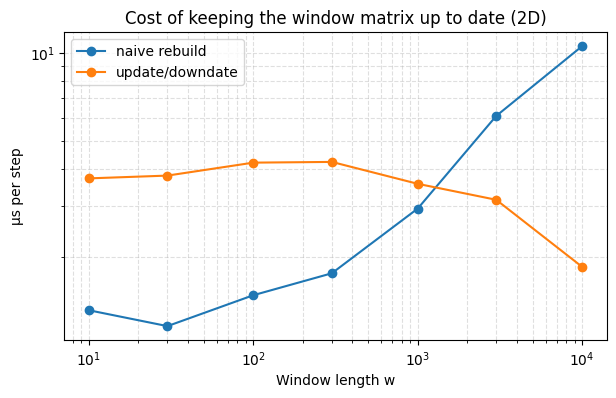

In [87]:
# Only the matrix maintenance: rebuild from the window vs two rank-one changes
def maintain_naive(X, w):
    for index in range(len(X)):
        window = X[max(0, index + 1 - w):index + 1]
        S = window.T @ window
    return S

def maintain_updown(X, w):
    S = np.zeros((2, 2))
    for index in range(len(X)):
        S += np.outer(X[index], X[index])
        if index >= w:
            S -= np.outer(X[index - w], X[index - w])
    return S

sweep_cost = [10, 30, 100, 300, 1000, 3000, 10000]
maintenance = {'naive rebuild': [], 'update/downdate': []}
for w in sweep_cost:
    maintenance['naive rebuild'].append(1e6 * best_time(lambda: maintain_naive(X_cost, w)) / cost_n)
    maintenance['update/downdate'].append(1e6 * best_time(lambda: maintain_updown(X_cost, w)) / cost_n)

fig, ax = plt.subplots(figsize=(7, 4))
for label, values in maintenance.items():
    ax.loglog(sweep_cost, values, marker='o', label=label)
ax.set_xlabel('Window length w')
ax.set_ylabel('µs per step')
ax.set_title('Cost of keeping the window matrix up to date (2D)')
ax.grid(True, which='both', linestyle='--', alpha=0.4)
ax.legend()
plt.show()


- **The update/downdate versions do not depend on $w$.** The naive recomputation grows with $w$ (from about $28$ to $51$ µs per step between $w=10$ and $w=5000$), but slowly, because for small windows the matrix product is cheaper than the Python overhead that every version pays.
- **TW-API is the cheapest version** (about $11$ µs per step), because it never diagonalizes anything. The rank-1 SVD window is the most expensive (about $55$ µs), because it solves two small eigenproblems per step. It is cheaper for $w=5000$ only because the first $5000$ of the $10000$ steps have no downdate.
- The differences that matter in high dimension ($O(wd^2)$ against $O(d^2)$ against $O(dr)$) can only be seen here as constant factors.

# 7. Window versus forgetting at equal noise

### Which $\alpha$ corresponds to a window of length $w$?

Both estimates are weighted averages of the terms $x_kx_k^\top$, with weights $c_k$ that sum to one:

- window: $c_k=1/w$ for $k=0,\dots,w-1$;
- forgetting: $c_k=\alpha(1-\alpha)^k$ for $k\geq 0$ (in the stationary limit).

For independent terms with variance $\sigma^2$, a weighted average has variance $\sigma^2\sum_k c_k^2$:

$$\text{window: }\sum_k c_k^2=\frac{1}{w},\qquad \text{forgetting: }\sum_k \alpha^2(1-\alpha)^{2k}=\frac{\alpha}{2-\alpha}.$$

Equal variance requires

$$w=\frac{2-\alpha}{\alpha}=\frac{2}{\alpha}-1\quad\Longleftrightarrow\quad \alpha=\frac{2}{w+1}.$$

Equivalently, $(\sum_k c_k)^2/\sum_k c_k^2$ is the effective sample size (Kish, 1965): a window has $w$ effective samples, and forgetting has $(2-\alpha)/\alpha\approx 2/\alpha$. The often quoted "memory" $1/\alpha$ is the time constant of the geometric weights, which is half the effective sample size.

The same $w$ also equalizes the **mean age** of the weights, which controls the lag when tracking a slow drift:

$$\text{window: }\sum_k k\,c_k=\frac{w-1}{2},\qquad\text{forgetting: }\sum_k k\,\alpha(1-\alpha)^k=\frac{1-\alpha}{\alpha},$$

and equating them again gives $w=2/\alpha-1$. With this matching the two methods have the same stationary noise and the same average delay. They differ only in the **shape** of the weight profile, that is, the weight a method gives to an observation as a function of its age.

This matches the reduced model of the thesis proposal, where the stationary error variance is $P^\ast=\sigma^2\alpha/(2\kappa)$: the factor $\alpha/2$ plays the role of $1/w$.


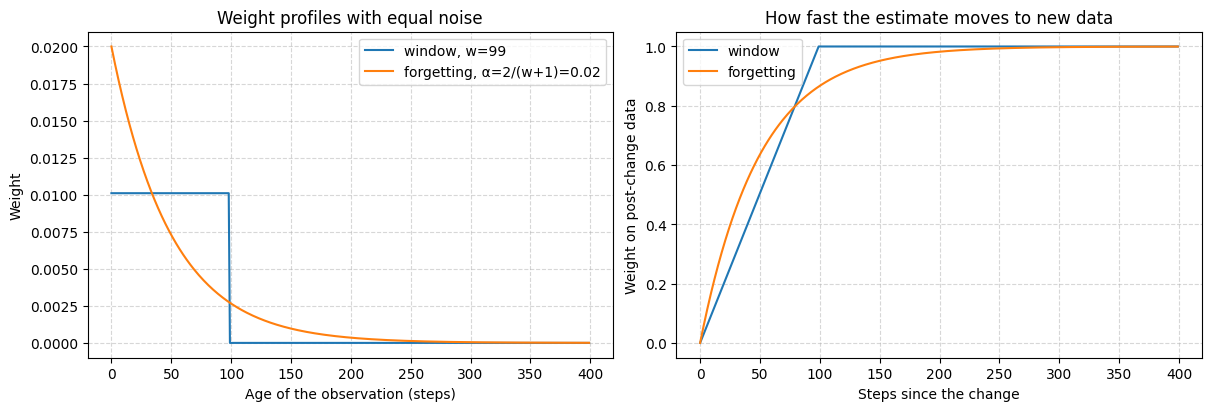

sum of squared weights: 0.01010 0.01010
mean age: 49.00 49.00


In [88]:
w = 99
alpha = matched_alpha(w)
lags = np.arange(0, 400)
window_weights = np.where(lags < w, 1 / w, 0)
forgetting_weights = alpha * (1 - alpha) ** lags

# fraction of the total weight carried by samples that arrived after a change, k steps ago
k = np.arange(0, 400)
window_new = np.minimum(k, w) / w
forgetting_new = 1 - (1 - alpha) ** k

fig, axes = plt.subplots(1, 2, figsize=(12, 4), constrained_layout=True)
axes[0].plot(lags, window_weights, label=f'window, w={w}')
axes[0].plot(lags, forgetting_weights, label=f'forgetting, α=2/(w+1)={alpha:g}')
axes[0].set_xlabel('Age of the observation (steps)')
axes[0].set_ylabel('Weight')
axes[0].set_title('Weight profiles with equal noise')
axes[1].plot(k, window_new, label='window')
axes[1].plot(k, forgetting_new, label='forgetting')
axes[1].set_xlabel('Steps since the change')
axes[1].set_ylabel('Weight on post-change data')
axes[1].set_title('How fast the estimate moves to new data')
for ax in axes:
    ax.grid(True, linestyle='--', alpha=0.5)
    ax.legend()
plt.show()

print('sum of squared weights:', f'{np.sum(window_weights**2):.5f}', f'{alpha / (2 - alpha):.5f}')
print('mean age:', f'{np.sum(lags * window_weights):.2f}', f'{(1 - alpha) / alpha:.2f}')

- **Weight profiles with equal noise.** In the window, each of the last $99$ observations counts the same ($1/99$), and older ones count zero: a hard cut. In forgetting, the newest observation counts twice as much ($0.02$), and older ones count less and less, without ever reaching zero. The two methods have the same noise, so this shape is the only difference between them.
- **How fast the estimate moves to new data after a change.** The window moves in a straight line: after $10$ steps $10\%$ of its weight is on new data, after $99$ steps $100\%$. Forgetting starts faster ($18\%$ after $10$ steps, $51\%$ after $35$) but slows down: after $99$ steps it is at $87\%$, and it never reaches $100\%$, because the old data keep a small weight. The curves cross after about $78$ steps.

### Four regimes, three window lengths

The three window methods of Part 1 against the two forgetting methods of `01_baselines` with the matched gain $\alpha=2/(w+1)$. With $w\in\{399,99,19\}$ the matched gains are exactly the gains of `01_baselines`, $0.005$, $0.02$ and $0.1$, so the forgetting rows reproduce the numbers of that notebook.

In [89]:
# Forgetting methods with the matched gains (the windows are reused from Part 1)
for scenario in scenarios:
    results['forgetting', scenario] = {w: run_method(lambda X: forgetting_pca(X, matched_alpha(w)), streams[scenario])
                                       for w in window_sizes}
    results['rank1_forgetting', scenario] = {w: run_method(lambda X: rank1_svd_pca(X, matched_alpha(w)), streams[scenario])
                                             for w in window_sizes}

compared = {'exact': lambda w: f'window w={w}',
            'svd': lambda w: f'rank-1 SVD window w={w}',
            'twapi': lambda w: f'TW-API w={w}',
            'forgetting': lambda w: f'forgetting α={matched_alpha(w):g}',
            'rank1_forgetting': lambda w: f'rank-1 SVD forgetting α={matched_alpha(w):g}'}

rows = []
for w in window_sizes:
    for key, name in compared.items():
        runs = results[key, 'abrupt'][w][0]
        delays = recovery_delays(runs, base_settings)
        recovered = np.isfinite(delays)
        median_delay = float(np.median(delays[recovered])) if recovered.any() else 'Not confirmed'
        rows.append([name(w), f'{runs[:, warmup:switch_step].mean():.5f}', f'{runs[:, switch_step:].mean():.5f}',
                     f'{recovered.sum()}/{len(runs)}', median_delay])
ut.show_table(['Abrupt regime', 'Pre-change mean E', 'Post-change mean E', 'Recovered', 'Median delay'], rows)

rows = []
for scenario in ['stationary', 'rotation', 'drift']:
    for w in window_sizes:
        for key, name in compared.items():
            runs, angles, _ = results[key, scenario][w]
            run_means = runs[:, warmup:].mean(axis=1)
            rows.append([scenario, name(w), f'{run_means.mean():.5f} +/- {run_means.std(ddof=1):.5f}',
                         f'{angles[:, warmup:].std(axis=1).mean():.2f}'])
ut.show_table(['Regime', 'Method', 'Mean E after warm-up (+/- SD of run means)', 'Mean angle-error SD (deg)'], rows)

| Abrupt regime | Pre-change mean E | Post-change mean E | Recovered | Median delay |
| --- | --- | --- | --- | --- |
| window w=399 | 0.00030 | 0.12385 | 20/20 | 304.0 |
| rank-1 SVD window w=399 | 0.00027 | 0.18879 | 19/20 | 419.0 |
| TW-API w=399 | 0.00029 | 0.15720 | 20/20 | 376.0 |
| forgetting α=0.005 | 0.00034 | 0.08937 | 20/20 | 260.5 |
| rank-1 SVD forgetting α=0.005 | 0.00031 | 0.12400 | 20/20 | 374.5 |
| window w=99 | 0.00125 | 0.03163 | 20/20 | 102.0 |
| rank-1 SVD window w=99 | 0.00099 | 0.07810 | 20/20 | 176.0 |
| TW-API w=99 | 0.00110 | 0.03971 | 20/20 | 120.5 |
| forgetting α=0.02 | 0.00123 | 0.02343 | 20/20 | 91.5 |
| rank-1 SVD forgetting α=0.02 | 0.00109 | 0.03146 | 20/20 | 116.0 |
| window w=19 | 0.00747 | 0.01256 | 20/20 | 55.0 |
| rank-1 SVD window w=19 | 0.00587 | 0.03259 | 20/20 | 124.0 |
| TW-API w=19 | 0.00623 | 0.01330 | 20/20 | 58.5 |
| forgetting α=0.1 | 0.00695 | 0.01096 | 20/20 | 53.5 |
| rank-1 SVD forgetting α=0.1 | 0.00617 | 0.01158 | 20/20 | 56.0 |


| Regime | Method | Mean E after warm-up (+/- SD of run means) | Mean angle-error SD (deg) |
| --- | --- | --- | --- |
| stationary | window w=399 | 0.00027 +/- 0.00014 | 0.81 |
| stationary | rank-1 SVD window w=399 | 0.00023 +/- 0.00013 | 0.73 |
| stationary | TW-API w=399 | 0.00025 +/- 0.00015 | 0.77 |
| stationary | forgetting α=0.005 | 0.00030 +/- 0.00012 | 0.88 |
| stationary | rank-1 SVD forgetting α=0.005 | 0.00027 +/- 0.00012 | 0.82 |
| stationary | window w=99 | 0.00123 +/- 0.00044 | 1.93 |
| stationary | rank-1 SVD window w=99 | 0.00099 +/- 0.00035 | 1.73 |
| stationary | TW-API w=99 | 0.00109 +/- 0.00040 | 1.81 |
| stationary | forgetting α=0.02 | 0.00121 +/- 0.00036 | 1.92 |
| stationary | rank-1 SVD forgetting α=0.02 | 0.00108 +/- 0.00033 | 1.81 |
| stationary | window w=19 | 0.00733 +/- 0.00094 | 4.89 |
| stationary | rank-1 SVD window w=19 | 0.00589 +/- 0.00076 | 4.32 |
| stationary | TW-API w=19 | 0.00619 +/- 0.00088 | 4.49 |
| stationary | forgetting α=0.1 | 0.00680 +/- 0.00083 | 4.71 |
| stationary | rank-1 SVD forgetting α=0.1 | 0.00608 +/- 0.00077 | 4.45 |
| rotation | window w=399 | 0.03811 +/- 0.00271 | 1.40 |
| rotation | rank-1 SVD window w=399 | 0.06740 +/- 0.00414 | 2.65 |
| rotation | TW-API w=399 | 0.04649 +/- 0.00298 | 1.55 |
| rotation | forgetting α=0.005 | 0.03141 +/- 0.00259 | 1.77 |
| rotation | rank-1 SVD forgetting α=0.005 | 0.04011 +/- 0.00292 | 2.06 |
| rotation | window w=99 | 0.00381 +/- 0.00103 | 1.96 |
| rotation | rank-1 SVD window w=99 | 0.01427 +/- 0.00250 | 2.34 |
| rotation | TW-API w=99 | 0.00446 +/- 0.00112 | 1.84 |
| rotation | forgetting α=0.02 | 0.00383 +/- 0.00097 | 1.97 |
| rotation | rank-1 SVD forgetting α=0.02 | 0.00428 +/- 0.00103 | 1.85 |
| rotation | window w=19 | 0.00744 +/- 0.00102 | 4.89 |
| rotation | rank-1 SVD window w=19 | 0.01000 +/- 0.00207 | 4.80 |
| rotation | TW-API w=19 | 0.00657 +/- 0.00107 | 4.51 |
| rotation | forgetting α=0.1 | 0.00693 +/- 0.00091 | 4.71 |
| rotation | rank-1 SVD forgetting α=0.1 | 0.00622 +/- 0.00087 | 4.45 |
| drift | window w=399 | 0.01273 +/- 0.00417 | 5.79 |
| drift | rank-1 SVD window w=399 | 0.01566 +/- 0.00655 | 5.73 |
| drift | TW-API w=399 | 0.01394 +/- 0.00483 | 5.95 |
| drift | forgetting α=0.005 | 0.00926 +/- 0.00301 | 4.86 |
| drift | rank-1 SVD forgetting α=0.005 | 0.01043 +/- 0.00367 | 5.05 |
| drift | window w=99 | 0.00469 +/- 0.00083 | 3.86 |
| drift | rank-1 SVD window w=99 | 0.00602 +/- 0.00175 | 3.83 |
| drift | TW-API w=99 | 0.00482 +/- 0.00086 | 3.89 |
| drift | forgetting α=0.02 | 0.00366 +/- 0.00064 | 3.39 |
| drift | rank-1 SVD forgetting α=0.02 | 0.00379 +/- 0.00068 | 3.44 |
| drift | window w=19 | 0.00823 +/- 0.00111 | 5.19 |
| drift | rank-1 SVD window w=19 | 0.00764 +/- 0.00097 | 4.78 |
| drift | TW-API w=19 | 0.00711 +/- 0.00101 | 4.82 |
| drift | forgetting α=0.1 | 0.00757 +/- 0.00092 | 4.97 |
| drift | rank-1 SVD forgetting α=0.1 | 0.00685 +/- 0.00086 | 4.72 |


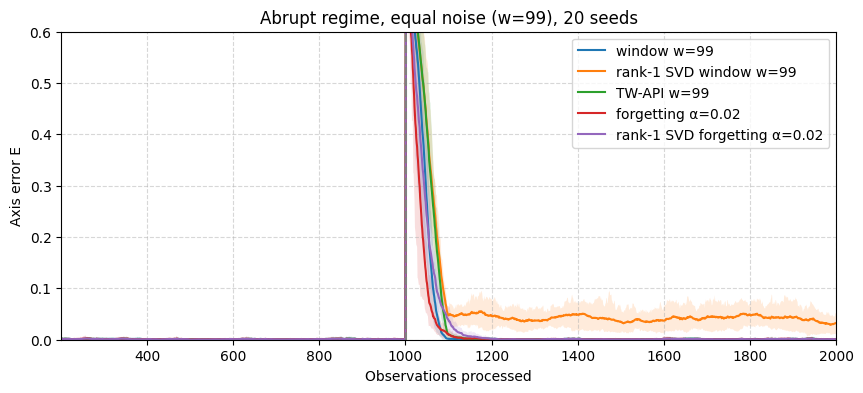

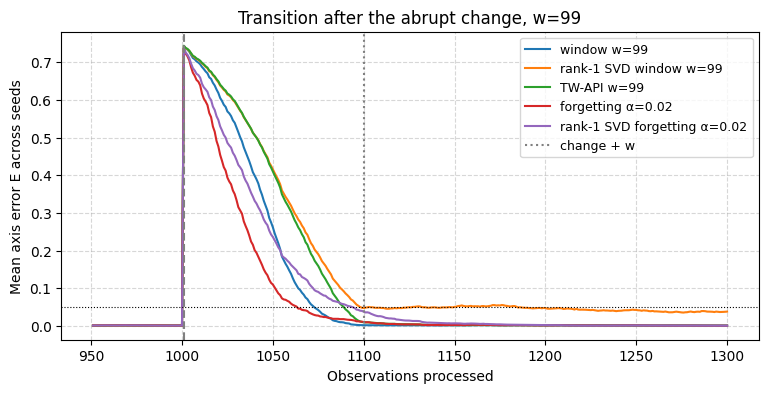

In [90]:
w = 99
keys = list(compared)
ut.plot_repeated_errors([results[key, 'abrupt'][w][0] for key in keys], [compared[key](w) for key in keys],
                        'Abrupt regime, equal noise (w=99), 20 seeds', warmup=warmup,
                        switch_step=switch_step, upper_limit=0.6)

fig, ax = plt.subplots(figsize=(9, 4))
zoom = np.arange(switch_step - 50, switch_step + 300)
for key in keys:
    ax.plot(zoom + 1, results[key, 'abrupt'][w][0].mean(axis=0)[zoom], label=compared[key](w))
ax.axvline(switch_step + 1, color='gray', linestyle='--')
ax.axvline(switch_step + w + 1, color='gray', linestyle=':', label='change + w')
ax.axhline(recovery_threshold, color='black', linestyle=':', linewidth=0.8)
ax.set_xlabel('Observations processed')
ax.set_ylabel('Mean axis error E across seeds')
ax.set_title('Transition after the abrupt change, w=99')
ax.grid(True, linestyle='--', alpha=0.5)
ax.legend(fontsize=9)
plt.show()

- **Abrupt change: forgetting wins at every $w$.** Lower post-change error ($0.0894$, $0.0234$, $0.0110$ against $0.1239$, $0.0316$, $0.0126$ for $w=399$, $99$, $19$) and shorter delays, because it moves to the new data faster (weight plot above). This holds with the default recovery threshold; with a very strict one ($0.01$) the window recovers first (`04_sensitivity_analysis`, A1).
- **Smooth rotation:** a tie at $w=99$ ($0.00381$ and $0.00383$); forgetting is better at the two ends, especially $w=399$ ($0.0314$ against $0.0381$).
- **Random drift: forgetting wins at every $w$** (for $w=99$, $0.00366$ against $0.00469$).


On this data no window version is clearly better than matched forgetting. The theoretical advantage of a window, a hard cut that removes the old regime completely after $w$ steps, does not show up in the mean error.

# 8. Sweep over the window length

Exact window against matched forgetting, $\alpha=2/(w+1)$, over a range of $w$ that includes the three window lengths of Part 1. Stationary, rotation and drift use the mean error after warm-up; for the abrupt regime the pre-change and post-change errors are shown separately.

In [91]:
sweep_windows = [10, 19, 35, 50, 75, 99, 150, 200, 300, 399, 600, 1000]
sweep = {}   # (scenario, family, w) -> runs
for scenario in scenarios:
    for w in sweep_windows:
        sweep[scenario, 'window', w] = run_method(lambda X: sliding_window_cov_pca(X, w), streams[scenario])[0]
        sweep[scenario, 'forgetting', w] = run_method(lambda X: forgetting_pca(X, matched_alpha(w)), streams[scenario])[0]

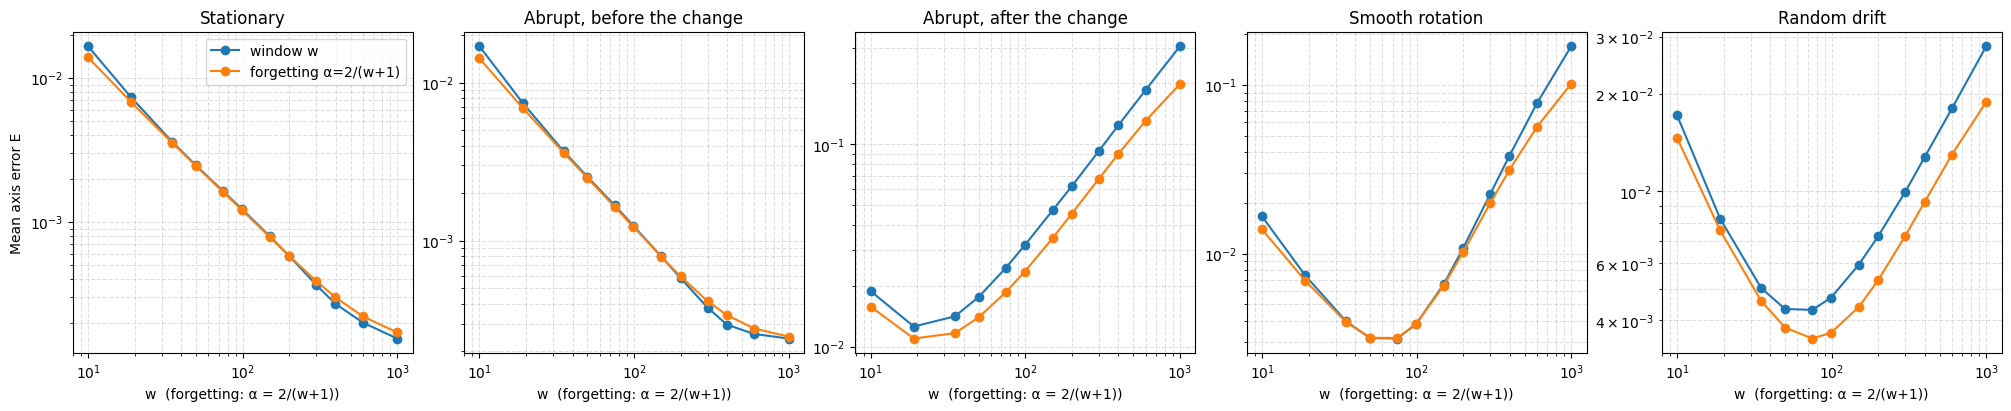

In [92]:
panels = [('stationary', 'Stationary', lambda r: r[:, warmup:]),
          ('abrupt', 'Abrupt, before the change', lambda r: r[:, warmup:switch_step]),
          ('abrupt', 'Abrupt, after the change', lambda r: r[:, switch_step:]),
          ('rotation', 'Smooth rotation', lambda r: r[:, warmup:]),
          ('drift', 'Random drift', lambda r: r[:, warmup:])]
fig, axes = plt.subplots(1, 5, figsize=(20, 4), constrained_layout=True)
for ax, (scenario, title, select) in zip(axes, panels):
    for kind, label in [('window', 'window w'), ('forgetting', 'forgetting α=2/(w+1)')]:
        values = [select(sweep[scenario, kind, w]).mean() for w in sweep_windows]
        ax.loglog(sweep_windows, values, marker='o', label=label)
    ax.set_title(title)
    ax.set_xlabel('w  (forgetting: α = 2/(w+1))')
    ax.grid(True, which='both', linestyle='--', alpha=0.4)
axes[0].set_ylabel('Mean axis error E')
axes[0].legend()
plt.show()

In [93]:
rows = []
for scenario, title, select in panels:
    best = {}
    for kind in ['window', 'forgetting']:
        values = [select(sweep[scenario, kind, w]).mean() for w in sweep_windows]
        index = int(np.argmin(values))
        best[kind] = (sweep_windows[index], values[index])
    rows.append([title, best['window'][0], f"{best['window'][1]:.5f}",
                 f"{matched_alpha(best['forgetting'][0]):.4f} (w={best['forgetting'][0]})", f"{best['forgetting'][1]:.5f}"])
ut.show_table(['Regime', 'Best w (window)', 'Error', 'Best α (forgetting)', 'Error'], rows)

| Regime | Best w (window) | Error | Best α (forgetting) | Error |
| --- | --- | --- | --- | --- |
| Stationary | 1000 | 0.00016 | 0.0020 (w=1000) | 0.00017 |
| Abrupt, before the change | 1000 | 0.00024 | 0.0020 (w=1000) | 0.00025 |
| Abrupt, after the change | 19 | 0.01256 | 0.1000 (w=19) | 0.01096 |
| Smooth rotation | 75 | 0.00314 | 0.0263 (w=75) | 0.00316 |
| Random drift | 75 | 0.00430 | 0.0263 (w=75) | 0.00351 |


- **Stationary and pre-change: decreasing in $w$**, with nearly equal curves. The best value is at the edge of the grid, as expected: with no change, more memory is always better. The small departures at the two ends are those discussed in Section 7.
- **After the abrupt change** the best value is small ($w=19$, $\alpha=0.1$), and forgetting is better at every $w$.
- **Smooth rotation:** the two curves almost coincide and have the same U shape, with the minimum at $w\approx75$ ($\alpha\approx0.026$).
- **Random drift:** same U shape and same location of the minimum, but forgetting is lower at every $w$.

The three window lengths of Part 1 cover the U shape. $w=19$ is dominated by noise, $w=99$ is close to the optimum for rotation and drift, and $w=399$ is dominated by lag. The best fixed memory depends on the regime, for windows as for forgetting, so a window does not avoid the gain-selection problem of the thesis.

# Summary

**Computing a window (Sections 1–6).**
- A non-trivial exact window replaces the $O(w)$ recomputation with one update and one downdate per step. Its rounding drift is negligible on these data, and a periodic rebuild (`recompute_every`) protects against extreme observations.
- A rank-1 SVD window with a truncated downdate is cheap in memory, but whenever the direction moves its downdate does not remove what was added. After an abrupt change it keeps a persistent angular error (about $11^\circ$ for $w=99$). In smooth rotation it adds a systematic extra lag, and under random drift a larger error without a fixed sign. A window has no decay, so an error that enters the state is not discounted.
- TW-API (Badeau et al., 2005) updates the direction directly. It removes each sample through the coordinate stored when it entered, so it does not have this error. It is the cheapest version and stays close to the exact window, with a little extra smoothing and lag. It needs $w\ge5$ here. It is an approximated power iteration (Badeau et al., 2005); Oja's update (notebook 03) is also a stochastic version of a power-iteration step.

**Which window to use (Sections 7–8).**
- A window of length $w$ has the same stationary noise as forgetting with $\alpha=2/(w+1)$ (equal effective sample size), and the same mean age of the weights.
- At equal noise, forgetting is better than the window after an abrupt change and under random drift, and equal in smooth rotation. No window version is clearly better than matched forgetting on these regimes.
- The best memory length depends on the regime (U-shaped error in $w$), exactly as for $\alpha$. A window does not remove the need to choose, or adapt, the memory.

## Basic checks

The full set of tests is in `tests/test_pca.py`. These short checks repeat the main ones on the notebook data.

In [94]:
test_X = streams['stationary'][seed][0][:100]

# A window at least as long as the stream agrees with cumulative PCA.
cum_q, cum_C = cumulative_pca(test_X)
for fn in [sliding_window_pca, sliding_window_cov_pca, lambda X, w: sliding_window_svd_pca(X, w, rank=2)]:
    win_q, win_C = fn(test_X, len(test_X))
    np.testing.assert_allclose(win_C, cum_C, atol=1e-12)
    np.testing.assert_allclose(axis_error(win_q, cum_q), 0, atol=1e-12)

# The final matrix is the covariance of the last w observations.
for fn in [sliding_window_pca, sliding_window_cov_pca, lambda X, w: sliding_window_svd_pca(X, w, rank=2)]:
    win_q, win_C = fn(test_X, 20)
    np.testing.assert_allclose(win_C, test_X[-20:].T @ test_X[-20:] / 20, atol=1e-10)

# Causality: the estimate at time t does not depend on later observations.
for fn in [sliding_window_pca, sliding_window_cov_pca, sliding_window_svd_pca]:
    full_q, _ = fn(test_X, 20)
    prefix_q, _ = fn(test_X[:40], 20)
    np.testing.assert_allclose(prefix_q, full_q[:40], atol=1e-12)

# A rank-1 window longer than the stream never downdates: it is rank-1 incremental PCA.
np.testing.assert_allclose(axis_error(sliding_window_svd_pca(test_X, 500)[0], incremental_pca(test_X)[0]), 0, atol=1e-10)

# Matched gain: equal sum of squared weights.
for w in window_sizes:
    a = matched_alpha(w)
    np.testing.assert_allclose(a / (2 - a), 1 / w)
# TW-API: unit directions, causal, close to the exact window on stationary data.
tw_q, _ = tw_api_pca(streams['stationary'][seed][0], 100)
np.testing.assert_allclose(np.linalg.norm(tw_q, axis=1), 1, atol=1e-12)
np.testing.assert_allclose(tw_api_pca(test_X[:40], 20)[0], tw_api_pca(test_X, 20)[0][:40], atol=1e-12)
assert axis_error(tw_q, sliding_window_cov_pca(streams['stationary'][seed][0], 100)[0])[warmup:].mean() < 1e-4

print('All checks passed.')

All checks passed.


## References

- M. Brand (2006). Fast low-rank modifications of the thin singular value decomposition. *Linear Algebra and its Applications*
- J. R. Bunch, C. P. Nielsen, D. C. Sorensen (1978). Rank-one modification of the symmetric eigenproblem. *Numerische Mathematik*
- R. Badeau, B. David, G. Richard (2005). Fast approximated power iteration subspace tracking. *IEEE Transactions on Signal Processing*
- L. Kish (1965). *Survey Sampling*. Wiley (effective sample size of a weighted average).
